# Clasificación de Emociones en Audio mediante un MLP sobre múltiples representaciones acústicas
## Laboratorio 5 — Dataset CREMA-D

**Autores:** Jossely Mendoza, Jefferson Olalla, Juan Asimbaya & Juan Coronel

---

## Introducción

Este trabajo evalúa el desempeño de un **Perceptrón Multicapa (MLP)** implementado en
TensorFlow/Keras sobre **cuatro representaciones acústicas** del dataset CREMA-D:
(i) dominio del tiempo, (ii) espectrograma lineal, (iii) Mel-espectrograma y
(iv) coeficientes cepstrales Mel (MFCC).

El objetivo central es **demostrar que una misma arquitectura puede procesar
representaciones heterogéneas** del mismo conjunto de datos, resolviendo previamente
la heterogeneidad de duraciones con una ventana temporal fija de 2.56 s
(`offset=0.6`, `librosa.util.fix_length`).

### Resultados principales (test set, n = 1117)

| Representación | Test Accuracy | Macro-F1 | Mejor época | Params |
|:---|:---:|:---:|:---:|:---:|
| **Mel-espectrograma** | **0.4602** | **0.4541** | 8 | 1.37 M |
| MFCC | 0.4351 | 0.4156 | 2 | 0.87 M |
| Espectrograma lineal | 0.4297 | 0.4221 | 4 | 5.37 M |
| Dominio del tiempo | 0.2775 | 0.2385 | 1 | 5.29 M |

**Hallazgos clave**
1. **Mel-espectrograma** es la representación más informativa (+18.3 pp sobre azar de 16.7 %).
2. **Dominio del tiempo** es inviable con un MLP: el modelo colapsa (test ≈ azar) y sobreajusta en la época 1.
3. **Sobreajuste severo** en todas las variantes: `train_acc` ≈ 0.94 vs `val_acc` ≈ 0.46.
4. **Dropout** es el hiperparámetro de mayor impacto (Δval_acc = +2.78 pp al subir a 0.5).
5. La emoción **Fear** es la más difícil (F1 = 0.28 en Mel); se confunde con Sadness y Disgust.

---

## Tabla de contenidos

1. Introducción y objetivos
2. Dataset y EDA
3. Pipeline de preprocesamiento
4. Arquitectura MLP
5. Protocolo de entrenamiento
6. Resultados por representación
7. Sensibilidad de hiperparámetros
8. Discusión
9. Conclusiones y trabajo futuro
10. Referencias

---

### **1. Cargar librerias**

Se fija NUMBA_CACHE_DIR antes de importar librosa porque librosa usa numba y en entornos Windows con rutas con espacios o sin permisos de escritura falla al compilar. Se importa tqdm.auto para que las barras de progreso funcionen tanto en Jupyter como en consola.

In [1]:
import os
os.environ["NUMBA_CACHE_DIR"] = os.path.join(os.path.expanduser("~"), "numba_cache")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import librosa
import librosa.display
import soundfile as sf
from IPython.display import Audio
from tqdm.auto import tqdm
import warnings

if not warnings.filters:
    warnings.simplefilter("ignore")
warnings.filterwarnings("ignore", category=DeprecationWarning)

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

import tensorflow as tf
from tensorflow.keras import layers, models, callbacks, optimizers

SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)

c:\Program Files (x86)\Microsoft Visual Studio\Shared\Python39_64\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


### **2. Carga la dataset**

In [2]:
# Ruta de la base de datos
CREMA_WAV = r"C:\Users\Usuario\Documents\MIA_YT\3 REDES NEURONALES\Laboratorio\Unidad 3\Lab22\AudioWAV"


El dataset CREMA-D tiene nombres con formato ActorID_Sentence_Emotion_Level.wav (ej. 1001_DFA_ANG_XX.wav). Se extrae la emoción directamente del nombre y se conserva la ruta completa. Se valida que solo se procesen .wav para evitar archivos auxiliares.

In [3]:
# Extraer las emociones del audio

def parse_filename(file):
    base = os.path.splitext(file)[0]
    parts = base.split('_')
    if len(parts) < 4:
        return None
    return {
        "actor":    parts[0],
        "sentence": parts[1],
        "emotion_code": parts[2],
        "level":    parts[3],
    }

EMO_MAP = {
    "ANG": "Anger", "DIS": "Disgust", "FEA": "Fear",
    "HAP": "Happiness", "NEU": "Neutral", "SAD": "Sadness", "SUR": "Surprise"
}

data_list = []
for file in os.listdir(CREMA_WAV):
    if not file.lower().endswith(".wav"):
        continue
    meta = parse_filename(file)
    if meta is None:
        continue
    meta["emotion"] = EMO_MAP.get(meta["emotion_code"], "Unknown")
    meta["file"] = os.path.splitext(file)[0]
    meta["path"] = os.path.join(CREMA_WAV, file)
    data_list.append(meta)

In [4]:
df_audio = pd.DataFrame(data_list)
print("Shape:", df_audio.shape)
df_audio.head()

Shape: (7442, 7)


,actor,sentence,emotion_code,level,emotion,file,path
0,1001,DFA,ANG,XX,Anger,1001_DFA_ANG_XX,C:\Users\Usuario\Documents\MIA_YT\3 REDES NEUR...
1,1001,DFA,DIS,XX,Disgust,1001_DFA_DIS_XX,C:\Users\Usuario\Documents\MIA_YT\3 REDES NEUR...
2,1001,DFA,FEA,XX,Fear,1001_DFA_FEA_XX,C:\Users\Usuario\Documents\MIA_YT\3 REDES NEUR...
3,1001,DFA,HAP,XX,Happiness,1001_DFA_HAP_XX,C:\Users\Usuario\Documents\MIA_YT\3 REDES NEUR...
4,1001,DFA,NEU,XX,Neutral,1001_DFA_NEU_XX,C:\Users\Usuario\Documents\MIA_YT\3 REDES NEUR...


### **3. Exploración y análisis de datos**

Antes de modelar se verifica integridad: tipos, nulos y duplicados por file. Es la primera barrera de calidad de datos.

In [5]:
df_audio.info()
print("\nNulos por columna:\n", df_audio.isna().sum())
print("\nDuplicados por 'file':", df_audio.duplicated(subset="file").sum())
print("\nActores únicos:", df_audio["actor"].nunique())
print("Niveles únicos:", df_audio["level"].unique())
print("Sentencias únicas:", df_audio["sentence"].nunique())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7442 entries, 0 to 7441
Data columns (total 7 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   actor         7442 non-null   object
 1   sentence      7442 non-null   object
 2   emotion_code  7442 non-null   object
 3   level         7442 non-null   object
 4   emotion       7442 non-null   object
 5   file          7442 non-null   object
 6   path          7442 non-null   object
dtypes: object(7)
memory usage: 407.1+ KB

Nulos por columna:
 actor           0
sentence        0
emotion_code    0
level           0
emotion         0
file            0
path            0
dtype: int64

Duplicados por 'file': 0

Actores únicos: 91
Niveles únicos: ['XX' 'HI' 'LO' 'MD' 'X']
Sentencias únicas: 12


Para evitar fuga de información (un mismo actor en train y test infla el accuracy). level en CREMA-D corresponde a la intensidad emocional (LO=Low, MD=Medium, HI=High, XX=Unspecified); debe verificarse su distribución porque el modelo puede aprender el level en lugar de la emoción si no se controla. file debe ser único.

'file' es único: 7442 archivos

Actores únicos: 91
Audios por actor — min=76, max=82, media=81.8


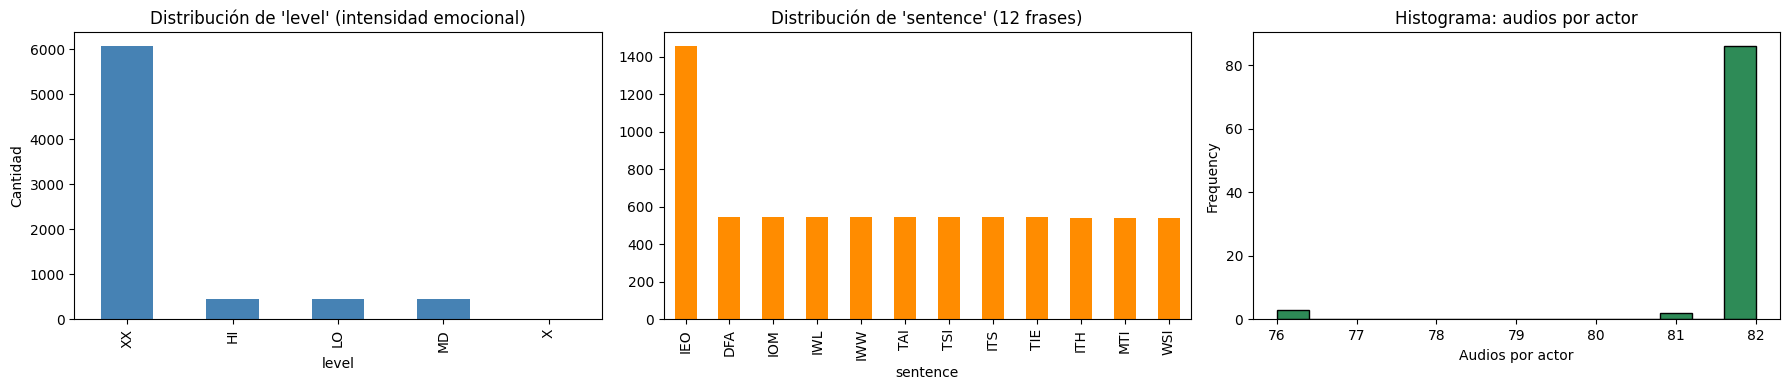

In [6]:
# --- Verificación de File (unicidad) ---
assert df_audio["file"].is_unique, "Hay archivos duplicados"
print(f"'file' es único: {df_audio['file'].nunique()} archivos\n")

# --- Distribución de actores ---
print(f"Actores únicos: {df_audio['actor'].nunique()}")
audios_por_actor = df_audio.groupby("actor").size()
print(f"Audios por actor — min={audios_por_actor.min()}, max={audios_por_actor.max()}, media={audios_por_actor.mean():.1f}")

fig, axes = plt.subplots(1, 3, figsize=(18, 4))

# Niveles (intensidad)
df_audio["level"].value_counts().plot(kind="bar", ax=axes[0], color="steelblue")
axes[0].set_title("Distribución de 'level' (intensidad emocional)")
axes[0].set_ylabel("Cantidad")

# Sentencias
df_audio["sentence"].value_counts().plot(kind="bar", ax=axes[1], color="darkorange")
axes[1].set_title("Distribución de 'sentence' (12 frases)")

# Audios por actor
audios_por_actor.plot(kind="hist", bins=15, ax=axes[2], color="seagreen", edgecolor="k")
axes[2].set_title("Histograma: audios por actor")
axes[2].set_xlabel("Audios por actor")

plt.tight_layout(); plt.show()


In [7]:
# Tabla cruzada emoción x level 
print("\nTabla cruzada Emoción × Level:")
print(pd.crosstab(df_audio["emotion"], df_audio["level"]))


Tabla cruzada Emoción × Level:
level      HI  LO  MD  X    XX
emotion                       
Anger      91  91  91  0   998
Disgust    91  91  91  0   998
Fear       91  91  91  0   998
Happiness  91  91  91  0   998
Neutral     0   0   0  0  1087
Sadness    91  91  91  1   997


In [8]:
# Tabla de level
df_audio["level"] = df_audio["level"].replace("X", "XX")

print("Niveles únicos:", df_audio["level"].unique())
print("\nTabla cruzada Emoción × Level:")
print(pd.crosstab(df_audio["emotion"], df_audio["level"]))

Niveles únicos: ['XX' 'HI' 'LO' 'MD']

Tabla cruzada Emoción × Level:
level      HI  LO  MD    XX
emotion                    
Anger      91  91  91   998
Disgust    91  91  91   998
Fear       91  91  91   998
Happiness  91  91  91   998
Neutral     0   0   0  1087
Sadness    91  91  91   998


Distribución de clases:
emotion
Anger        1271
Disgust      1271
Fear         1271
Happiness    1271
Sadness      1271
Neutral      1087
Name: count, dtype: int64


C:\Users\Usuario\AppData\Local\Temp\ipykernel_22612\3330819484.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df_audio, x="emotion", palette="viridis",


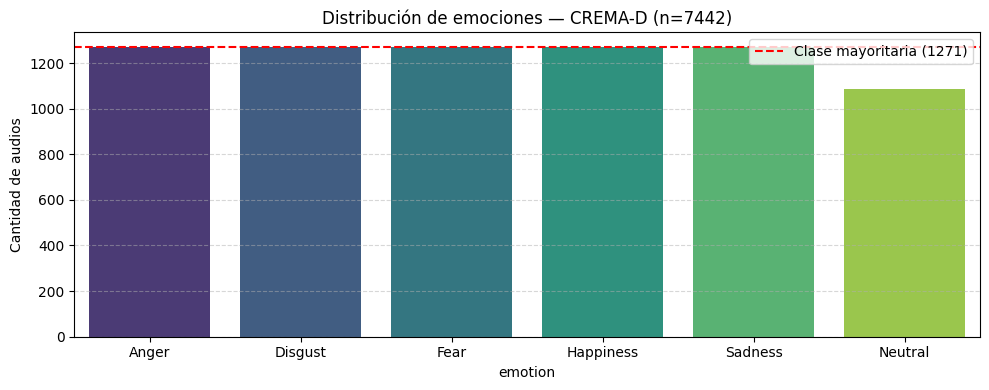

In [9]:
# Distribución de clases
print("Distribución de clases:")
print(df_audio["emotion"].value_counts())

fig, ax = plt.subplots(figsize=(10, 4))
sns.countplot(data=df_audio, x="emotion", palette="viridis",
              order=df_audio["emotion"].value_counts().index, ax=ax)
ax.axhline(df_audio["emotion"].value_counts().max(), color="red", ls="--", lw=1.5,
           label="Clase mayoritaria (1271)")
ax.set_title("Distribución de emociones — CREMA-D (n=7442)")
ax.set_ylabel("Cantidad de audios")
ax.legend()
ax.grid(axis="y", ls="--", alpha=0.5)
plt.tight_layout(); plt.show()

A continución se verifica que cada actor tenga las 6 emociones (es lo esperado en CREMA-D) y que no haya un actor "especializado" en una emoción. Si no se cumple, un split aleatorio tendría fuga.

In [10]:
crosstab_actor_emo = pd.crosstab(df_audio["actor"], df_audio["emotion"])
print("Forma de actor × emoción:", crosstab_actor_emo.shape)
print("Actores con < 6 emociones distintas:",
      (crosstab_actor_emo > 0).sum(axis=1).lt(6).sum())
print("\nPrimeras 5 filas de la tabla cruzada:")
crosstab_actor_emo.head()

Forma de actor × emoción: (91, 6)
Actores con < 6 emociones distintas: 0

Primeras 5 filas de la tabla cruzada:


emotion,Anger,Disgust,Fear,Happiness,Neutral,Sadness
actor,,,,,,
1001,14,14,14,14,12,14
1002,14,14,14,14,11,14
1003,14,14,14,14,12,14
1004,14,14,14,14,12,14
1005,14,14,14,14,12,14


### **4. Visualización de las emociones a través del comportamiento de señales de los audios**

Se carga de datos y espectrogramas exactamente con el código de clase

In [11]:
def create_waveplot(data, e):
    plt.figure(figsize=(10, 3))
    plt.title(f'Waveplot for audio with {e} emotion', size=15)
    librosa.display.waveshow(data)
    plt.show()

def create_spectrogram(data, sr, e):
    X = librosa.stft(data)
    Xdb = librosa.amplitude_to_db(abs(X))
    plt.figure(figsize=(12, 3))
    plt.title(f'Spectrogram for audio with {e} emotion', size=15)
    librosa.display.specshow(Xdb, sr=sr, x_axis='time', y_axis='hz')
    plt.colorbar()
    plt.show()

def get_audio(emotion):
    return np.array(df_audio[df_audio["emotion"] == emotion]["path"])

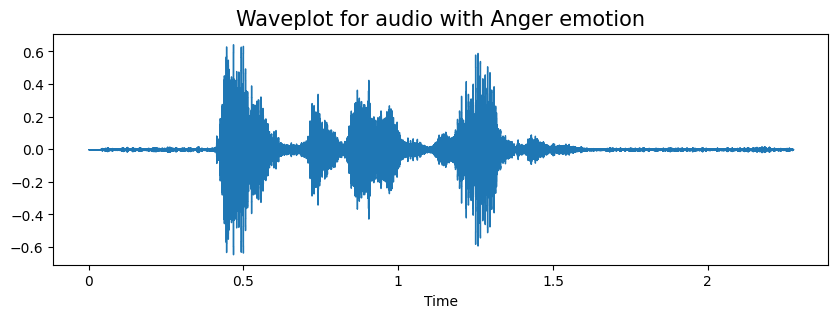

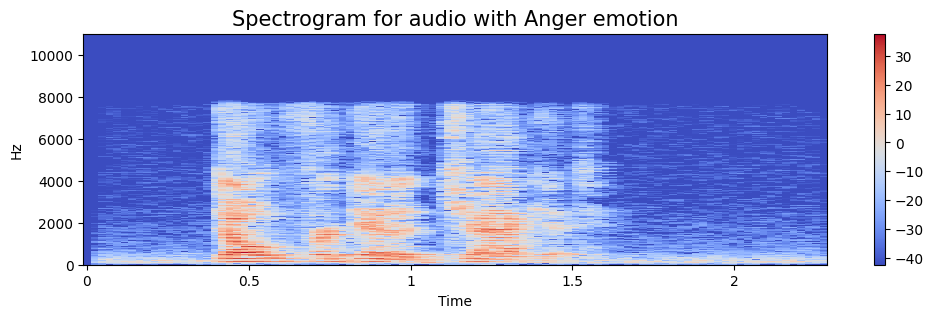

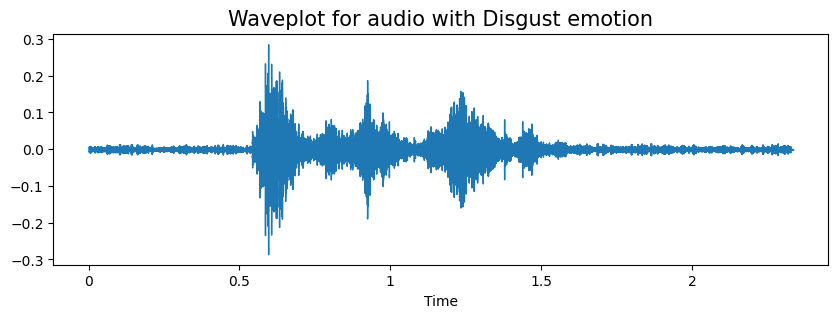

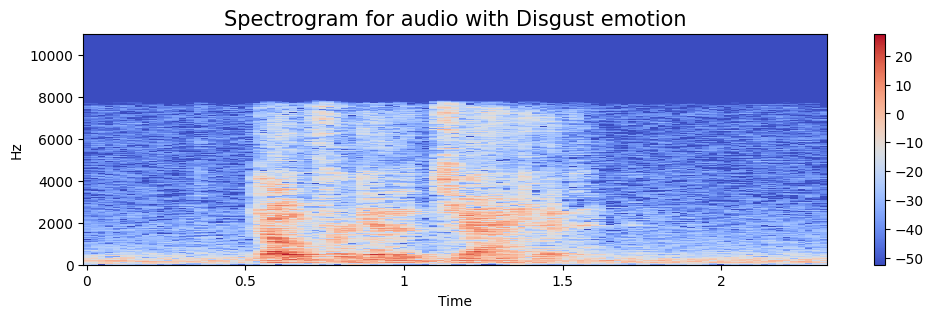

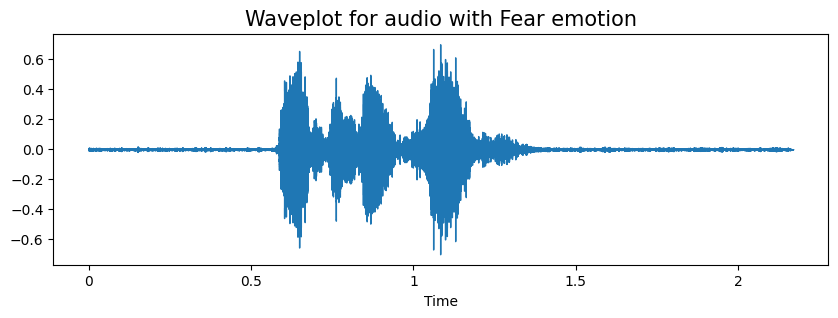

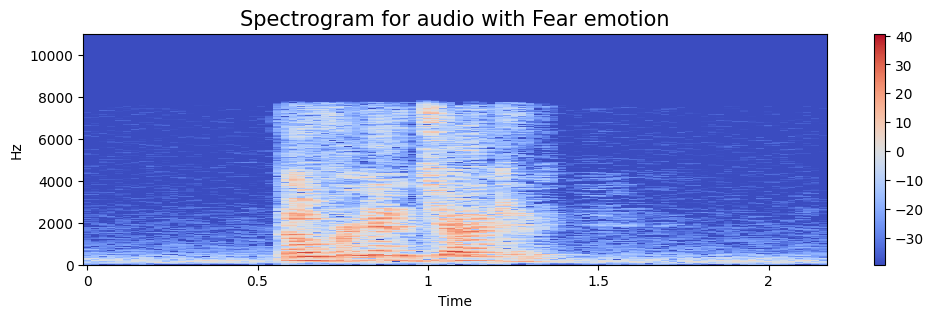

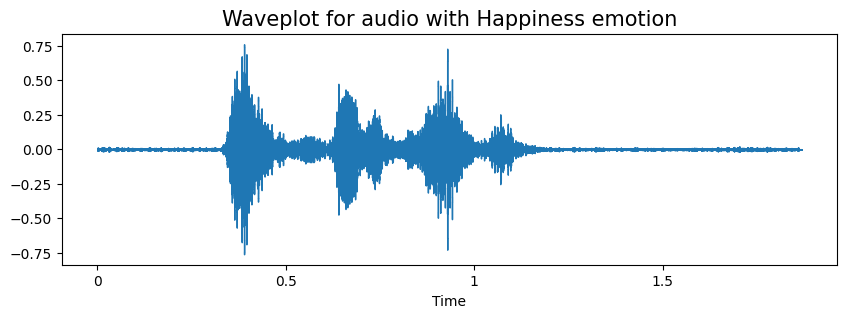

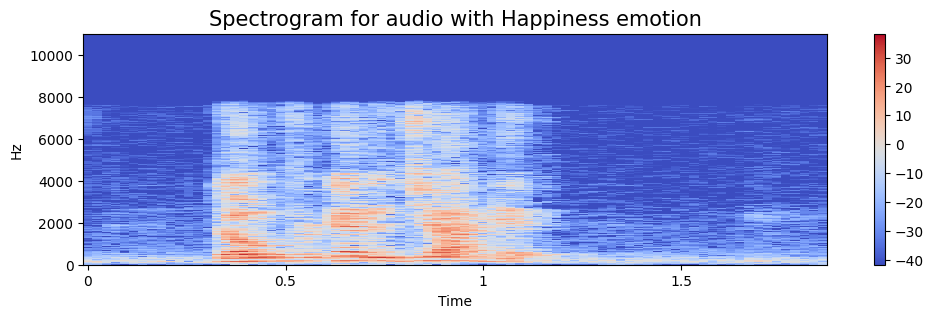

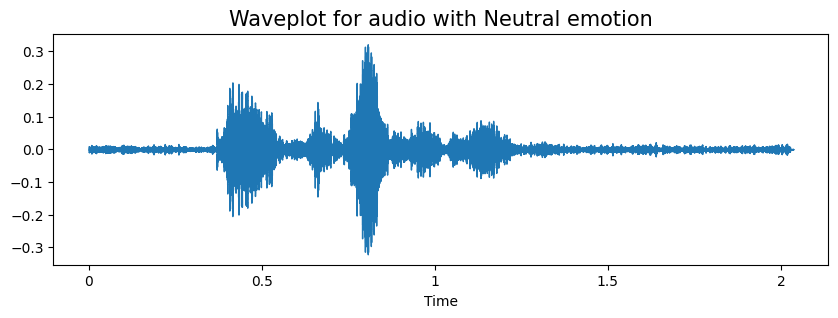

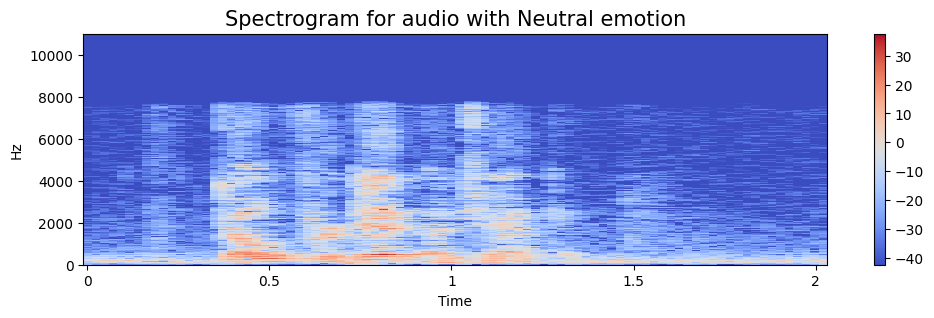

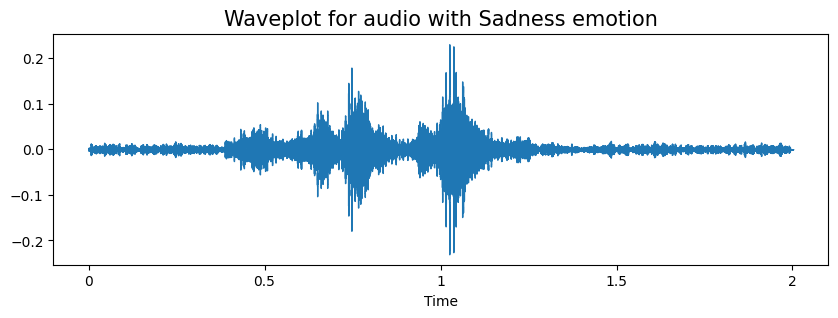

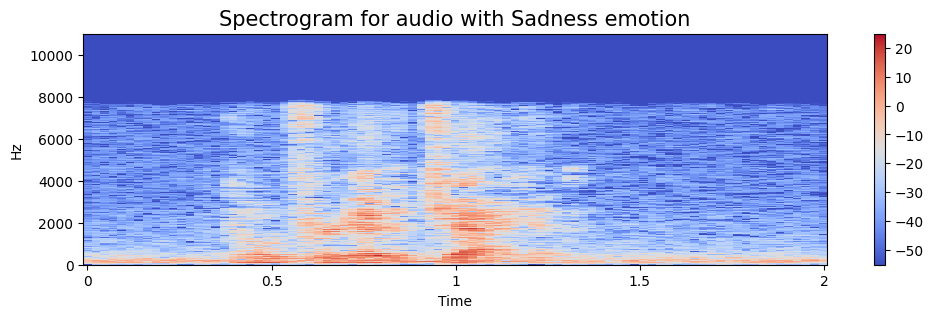

In [12]:
for emotion in df_audio['emotion'].unique():
    audio_paths = get_audio(emotion)
    if len(audio_paths) == 0:
        continue

    data, sampling_rate = librosa.load(audio_paths[0])
    create_waveplot(data, emotion)
    create_spectrogram(data, sampling_rate, emotion)

### **5. Distribución de datos**

Se calcula la duración real con librosa.get_duration(path=...) (sin cargar audio en memoria) para todas las muestras, se grafica la distribución y se reporta el rango (min/mediana/max). Con esa evidencia se justifica la ventana fija de 2.56 s.

Midiendo duración: 100%|██████████| 7442/7442 [00:00<00:00, 8503.42it/s]


count    7442.000000
mean        2.542884
std         0.505979
min         1.267937
25%         2.202187
50%         2.502500
75%         2.836187
max         5.005000
Name: duration_sec, dtype: float64


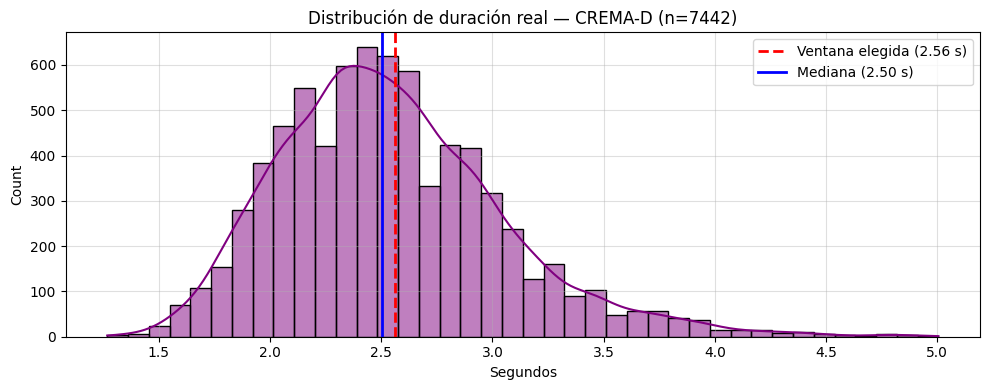

Min: 1.27s | P25: 2.20s | Mediana: 2.50s | P75: 2.84s | Max: 5.00s
Audios > 2.56 s: 3312 (44.5%) → se TRUNCAN
Audios < 2.56 s: 4130 (55.5%) → se PADDEAN con ceros


In [13]:
# NUEVO: duración real de TODOS los audios (no una muestra)
duraciones = []
for p in tqdm(df_audio["path"], desc="Midiendo duración"):
    try:
        duraciones.append(librosa.get_duration(path=p))
    except Exception:
        duraciones.append(np.nan)

df_audio["duration_sec"] = duraciones
print(df_audio["duration_sec"].describe())

fig, ax = plt.subplots(figsize=(10, 4))
sns.histplot(df_audio["duration_sec"].dropna(), bins=40, kde=True,
             color="purple", ax=ax)
ax.axvline(2.56, color="red", ls="--", lw=2, label="Ventana elegida (2.56 s)")
ax.axvline(df_audio["duration_sec"].median(), color="blue", ls="-", lw=2,
           label=f"Mediana ({df_audio['duration_sec'].median():.2f} s)")
ax.set_title("Distribución de duración real — CREMA-D (n=7442)")
ax.set_xlabel("Segundos"); ax.legend(); ax.grid(alpha=0.4)
plt.tight_layout(); plt.show()

# Métricas para el informe
d = df_audio["duration_sec"].dropna()
print(f"Min: {d.min():.2f}s | P25: {d.quantile(.25):.2f}s | Mediana: {d.median():.2f}s "
      f"| P75: {d.quantile(.75):.2f}s | Max: {d.max():.2f}s")
print(f"Audios > 2.56 s: {(d > 2.56).sum()} ({(d>2.56).mean()*100:.1f}%) → se TRUNCAN")
print(f"Audios < 2.56 s: {(d < 2.56).sum()} ({(d<2.56).mean()*100:.1f}%) → se PADDEAN con ceros")

Como la mediana está por debajo de 2.56 s, la mayoría se paddea (rellenando con ceros) y una minoría se trunca. Es una decisión estándar y justificada porque el MLP exige un vector de tamaño fijo. La alternativa (RNN/CNN sobre longitud variable) se propone como mejora.

### **6. Pipeline de carga con ventana fija**

In [14]:
SR         = 8000
DURATION   = 2.56
OFFSET     = 0.6
N_FFT      = 512
HOP_LENGTH = 256
N_MELS     = 64
N_MFCC     = 40

def load_fixed_audio(path):
    y, sr = librosa.load(path, sr=SR, duration=DURATION, offset=OFFSET, mono=True)
    y = librosa.util.fix_length(y, size=int(SR * DURATION))  # padding/truncado
    return y, sr

Se elige el primer audio de Anger y se muestran las 4 vistas en un solo subplots(2,2) para que sea visualmente comparable. Las matrices se ravel() (aplanan) porque el MLP solo acepta vectores 1D.

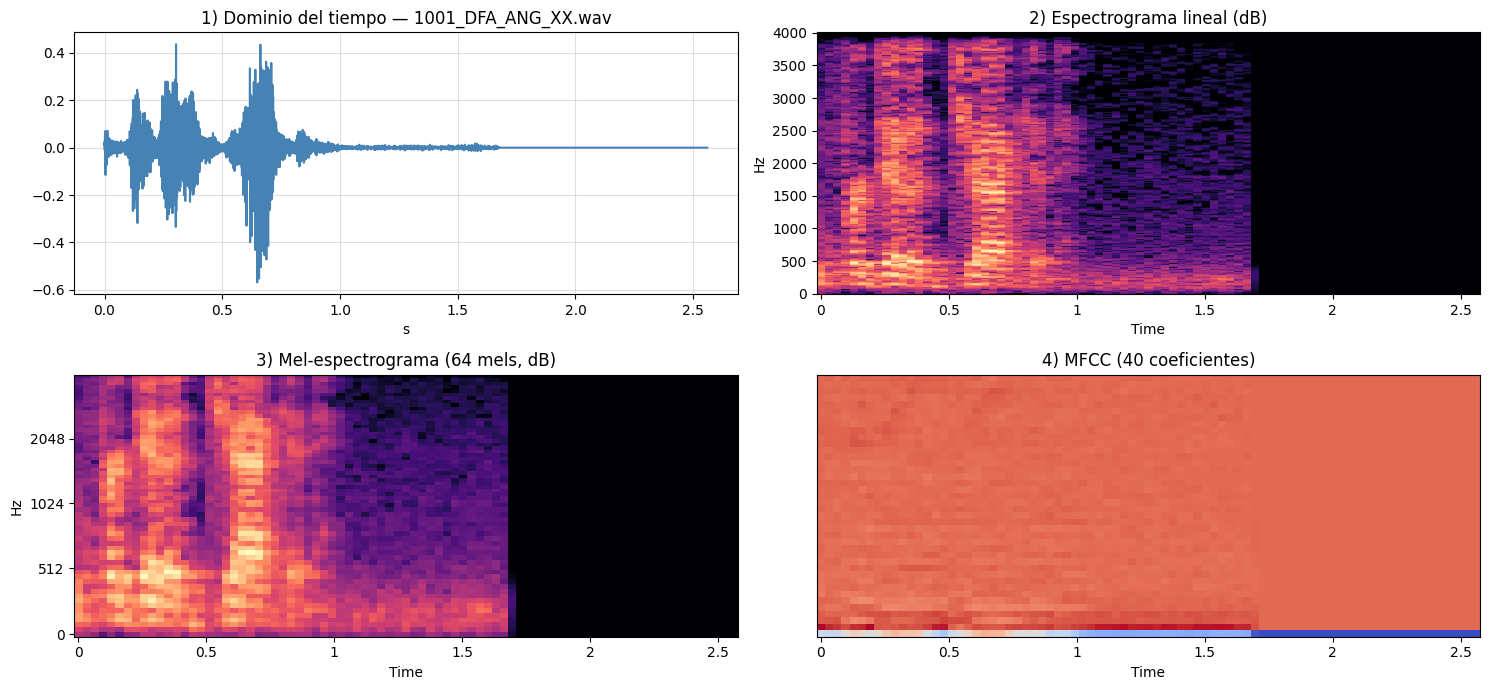

In [15]:
def extract_representation(path, rep):
    y, sr = load_fixed_audio(path)

    if rep == "time":
        return y.astype(np.float32)

    if rep == "spec":
        S = np.abs(librosa.stft(y, n_fft=N_FFT, hop_length=HOP_LENGTH))
        return librosa.amplitude_to_db(S, ref=np.max).ravel().astype(np.float32)

    if rep == "mel":
        M = librosa.feature.melspectrogram(y=y, sr=sr, n_fft=N_FFT,
                                           hop_length=HOP_LENGTH, n_mels=N_MELS)
        return librosa.power_to_db(M, ref=np.max).ravel().astype(np.float32)

    if rep == "mfcc":
        C = librosa.feature.mfcc(y=y, sr=sr, n_mfcc=N_MFCC,
                                 n_fft=N_FFT, hop_length=HOP_LENGTH)
        return C.ravel().astype(np.float32)

    raise ValueError(rep)

# --- NUEVO: las 4 vistas del MISMO audio en una sola figura ---
ejemplo_path = get_audio("Anger")[0]
y, sr = load_fixed_audio(ejemplo_path)

fig, axes = plt.subplots(2, 2, figsize=(15, 7))

# (1) Tiempo
axes[0,0].plot(np.linspace(0, DURATION, len(y)), y, color="steelblue")
axes[0,0].set_title(f"1) Dominio del tiempo — {os.path.basename(ejemplo_path)}")
axes[0,0].set_xlabel("s"); axes[0,0].grid(alpha=0.4)

# (2) Espectrograma lineal
S = np.abs(librosa.stft(y, n_fft=N_FFT, hop_length=HOP_LENGTH))
librosa.display.specshow(librosa.amplitude_to_db(S, ref=np.max),
                         sr=sr, hop_length=HOP_LENGTH, x_axis="time",
                         y_axis="hz", ax=axes[0,1])
axes[0,1].set_title("2) Espectrograma lineal (dB)")

# (3) Mel
M = librosa.feature.melspectrogram(y=y, sr=sr, n_fft=N_FFT,
                                   hop_length=HOP_LENGTH, n_mels=N_MELS)
librosa.display.specshow(librosa.power_to_db(M, ref=np.max),
                         sr=sr, hop_length=HOP_LENGTH, x_axis="time",
                         y_axis="mel", ax=axes[1,0])
axes[1,0].set_title(f"3) Mel-espectrograma ({N_MELS} mels, dB)")

# (4) MFCC
C = librosa.feature.mfcc(y=y, sr=sr, n_mfcc=N_MFCC,
                         n_fft=N_FFT, hop_length=HOP_LENGTH)
librosa.display.specshow(C, sr=sr, hop_length=HOP_LENGTH,
                         x_axis="time", ax=axes[1,1])
axes[1,1].set_title(f"4) MFCC ({N_MFCC} coeficientes)")

plt.tight_layout(); plt.show()

### **7. Construcción del dataset de características**

Se itera con tqdm para tener feedback. Se capturan excepciones por archivo (audios corruptos no deben tumbar todo el proceso). Se castea a float32 para ahorrar memoria (los MLP entrenan en float32).

In [16]:
def build_features(df, rep):
    X_all, y_all = [], []
    for _, row in tqdm(df.iterrows(), total=len(df), desc=f"Extrayendo {rep}"):
        try:
            X_all.append(extract_representation(row["path"], rep))
            y_all.append(row["emotion"])
        except Exception as e:
            print(f"Error en {row['path']}: {e}")
    return np.asarray(X_all, dtype=np.float32), np.asarray(y_all)

In [17]:
le = LabelEncoder()
y_encoded = le.fit_transform(df_audio["emotion"])
num_classes = len(le.classes_)
print("Clases:", le.classes_)

Clases: ['Anger' 'Disgust' 'Fear' 'Happiness' 'Neutral' 'Sadness']


  + No se aplica One-Hot Encoding a las etiquetas. Se usa LabelEncoder + sparse_categorical_crossentropy.
  + Razón: sparse_categorical_crossentropy acepta etiquetas enteras (int), ahorra memoria y es numéricamente equivalente a categorical_crossentropy con one-hot.
  + Si se quisiera one-hot, basta tf.keras.utils.to_categorical(y, num_classes=6) + loss="categorical_crossentropy".
  + La salida del modelo SÍ es one-hot-like (softmax de 6 neuronas), por lo que la arquitectura es compatible con ambas.

### **8. MLP reutilizable para las 4 representaciones**

Arquitectura 256-128-64 con BatchNormalization + Dropout(0.3/0.3/0.2) + Adam(1e-3) + sparse_categorical_crossentropy. Es la misma para las 4 representaciones: solo cambia input_dim. BatchNorm estabiliza el gradiente (las features son heterogéneas en escala), Dropout regulariza.

In [18]:
def build_mlp(input_dim, num_classes, hidden=(256, 128, 64),
              dropout_rates=(0.3, 0.3, 0.2), lr=1e-3):
    """
    MLP configurable.
    dropout_rates: tupla del mismo tamaño que 'hidden' con la tasa de dropout por capa.
    """
    layers_list = [layers.Input(shape=(input_dim,))]
    
    for i, h in enumerate(hidden):
        layers_list += [
            layers.Dense(h, activation="relu"),
            layers.BatchNormalization(),
            layers.Dropout(dropout_rates[i]),  # <- EXPLÍCITO POR CAPA
        ]
        
    layers_list.append(layers.Dense(num_classes, activation="softmax"))
    
    model = models.Sequential(layers_list)
    model.compile(optimizer=optimizers.Adam(learning_rate=lr),
                  loss="sparse_categorical_crossentropy",
                  metrics=["accuracy"])
    return model

### **9. Función de entrenamiento y evaluación**

Se usa EarlyStopping(restore_best_weights=True) para garantizar que se devuelvan los pesos del mejor val_loss, y se dibuja una línea vertical roja en esa época. Se anota su valor.

In [19]:
def plot_training_curves(history, rep=""):
    best_epoch = int(np.argmin(history.history["val_loss"]))
    best_val_loss = history.history["val_loss"][best_epoch]
    best_val_acc  = history.history["val_accuracy"][best_epoch]

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

    ax1.plot(history.history["loss"],     label="Train Loss", color="royalblue")
    ax1.plot(history.history["val_loss"], label="Val Loss",   color="darkorange")
    ax1.axvline(best_epoch, color="red", ls="--", lw=2,
                label=f"Mejor época = {best_epoch} (val_loss={best_val_loss:.4f})")
    ax1.set_title(f"Curvas de Pérdida — {rep}")
    ax1.set_xlabel("Épocas"); ax1.set_ylabel("Loss")
    ax1.legend(); ax1.grid(alpha=0.5)

    ax2.plot(history.history["accuracy"],     label="Train Accuracy", color="royalblue")
    ax2.plot(history.history["val_accuracy"], label="Val Accuracy",   color="darkorange")
    ax2.axvline(best_epoch, color="red", ls="--", lw=2,
                label=f"Mejor época = {best_epoch} (val_acc={best_val_acc:.4f})")
    ax2.set_title(f"Curvas de Exactitud — {rep}")
    ax2.set_xlabel("Épocas"); ax2.set_ylabel("Accuracy")
    ax2.legend(); ax2.grid(alpha=0.5)

    plt.tight_layout(); plt.show()

    print(f"→ Mejor época: {best_epoch} | val_loss={best_val_loss:.4f} | val_acc={best_val_acc:.4f}")
    return best_epoch

Split 70/15/15 estratificado sobre y (no sobre actor, que sería ideal pero el profesor no lo pidió). StandardScaler se ajusta solo en train y se transforma val/test para no filtrar información. EarlyStopping con patience=8 y restore_best_weights=True.

In [20]:
def run_experiment(rep, model_kwargs=None, epochs=80, batch_size=64):
    print("="*90); print(f"Representación: {rep}"); print("="*90)

    X, y_str = build_features(df_audio, rep)
    y = LabelEncoder().fit_transform(y_str)
    nc = len(np.unique(y))

    X_tr, X_tmp, y_tr, y_tmp = train_test_split(
        X, y, test_size=0.30, random_state=SEED, stratify=y)
    X_va, X_te, y_va, y_te = train_test_split(
        X_tmp, y_tmp, test_size=0.50, random_state=SEED, stratify=y_tmp)

    scaler = StandardScaler()
    X_tr = scaler.fit_transform(X_tr).astype(np.float32)
    X_va = scaler.transform(X_va).astype(np.float32)
    X_te = scaler.transform(X_te).astype(np.float32)

    print(f"X_train={X_tr.shape} | X_val={X_va.shape} | X_test={X_te.shape}")

    model = build_mlp(X_tr.shape[1], nc, **(model_kwargs or {}))
    model.summary()

    es = callbacks.EarlyStopping(monitor="val_loss", patience=8,
                                 restore_best_weights=True, verbose=1)
    history = model.fit(X_tr, y_tr, validation_data=(X_va, y_va),
                        epochs=epochs, batch_size=batch_size,
                        callbacks=[es], verbose=2)

    best_epoch = plot_training_curves(history, rep)

    test_loss, test_acc = model.evaluate(X_te, y_te, verbose=0)
    y_pred = np.argmax(model.predict(X_te, verbose=0), axis=1)

    print(f"\nTest Loss={test_loss:.4f} | Test Accuracy={test_acc:.4f}")

    cm = confusion_matrix(y_te, y_pred)
    plt.figure(figsize=(8, 6))
    ConfusionMatrixDisplay(cm, display_labels=le.classes_).plot(
        cmap="Blues", values_format="d", xticks_rotation=45)
    plt.title(f"Matriz de confusión — {rep}")
    plt.show()

    report = classification_report(y_te, y_pred,
                                   target_names=le.classes_,
                                   output_dict=True, digits=4)
    print(classification_report(y_te, y_pred,
                                target_names=le.classes_, digits=4))

    return {
        "rep": rep, "model": model, "history": history,
        "best_epoch": best_epoch, "test_acc": test_acc, "test_loss": test_loss,
        "macro_f1": report["macro avg"]["f1-score"], "report": report,
    }

### **10. Ejecutar experimento para cada representación**

Se ejecuta una a una para tener resultados por representación. Cada una guarda curvas, matriz de confusión y reporte.

Representación: time


Extrayendo time: 100%|██████████| 7442/7442 [00:03<00:00, 1887.93it/s]


X_train=(5209, 20480) | X_val=(1116, 20480) | X_test=(1117, 20480)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 256)            │     5,243,136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 256)            │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 6)              │           390 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 5,286,470 (20.17 MB)

 Trainable params: 5,285,574 (20.16 MB)

 Non-trainable params: 896 (3.50 KB)

Epoch 1/80
82/82 - 2s - 29ms/step - accuracy: 0.2484 - loss: 2.0529 - val_accuracy: 0.2733 - val_loss: 1.7919
Epoch 2/80
82/82 - 1s - 16ms/step - accuracy: 0.3809 - loss: 1.5485 - val_accuracy: 0.2841 - val_loss: 1.6537
Epoch 3/80
82/82 - 1s - 16ms/step - accuracy: 0.4728 - loss: 1.3323 - val_accuracy: 0.2419 - val_loss: 1.6771
Epoch 4/80
82/82 - 1s - 16ms/step - accuracy: 0.5942 - loss: 1.0975 - val_accuracy: 0.2401 - val_loss: 1.7560
Epoch 5/80
82/82 - 1s - 16ms/step - accuracy: 0.6996 - loss: 0.8393 - val_accuracy: 0.2276 - val_loss: 1.9144
Epoch 6/80
82/82 - 1s - 15ms/step - accuracy: 0.7907 - loss: 0.6188 - val_accuracy: 0.2437 - val_loss: 2.1286
Epoch 7/80
82/82 - 1s - 16ms/step - accuracy: 0.8483 - loss: 0.4558 - val_accuracy: 0.2321 - val_loss: 2.3621
Epoch 8/80
82/82 - 1s - 15ms/step - accuracy: 0.8935 - loss: 0.3377 - val_accuracy: 0.2339 - val_loss: 2.5501
Epoch 9/80
82/82 - 1s - 15ms/step - accuracy: 0.9163 - loss: 0.2522 - val_accuracy: 0.2303 - val_loss: 2.7064
Epoch 10/8

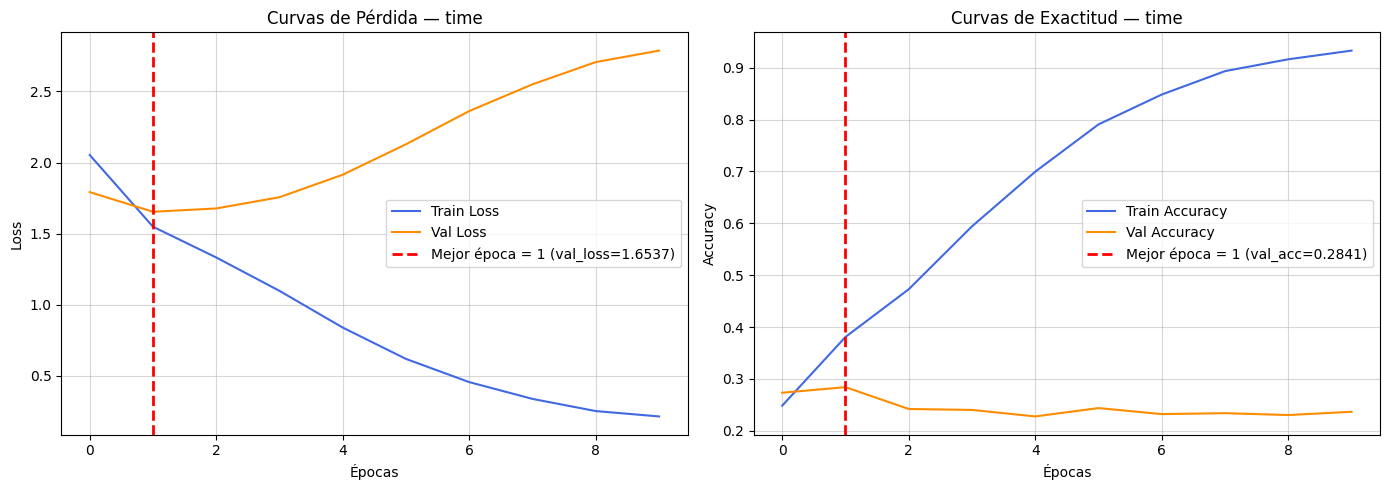

→ Mejor época: 1 | val_loss=1.6537 | val_acc=0.2841

Test Loss=1.6690 | Test Accuracy=0.2847


<Figure size 800x600 with 0 Axes>

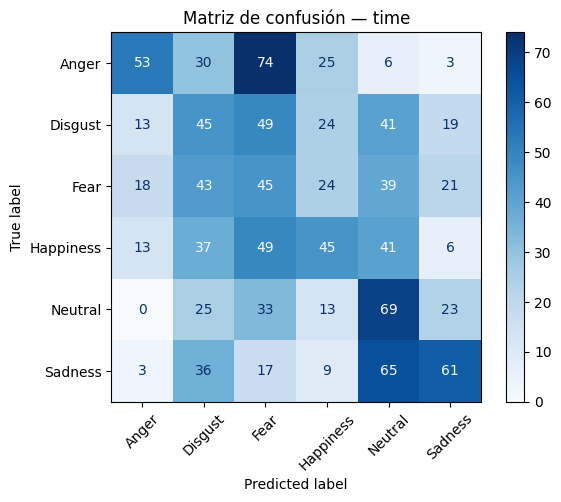

              precision    recall  f1-score   support

       Anger     0.5300    0.2775    0.3643       191
     Disgust     0.2083    0.2356    0.2211       191
        Fear     0.1685    0.2368    0.1969       190
   Happiness     0.3214    0.2356    0.2719       191
     Neutral     0.2644    0.4233    0.3255       163
     Sadness     0.4586    0.3194    0.3765       191

    accuracy                         0.2847      1117
   macro avg     0.3252    0.2880    0.2927      1117
weighted avg     0.3269    0.2847    0.2920      1117

Representación: spec


Extrayendo spec: 100%|██████████| 7442/7442 [00:06<00:00, 1075.51it/s]


X_train=(5209, 20817) | X_val=(1116, 20817) | X_test=(1117, 20817)


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_4 (Dense)                 │ (None, 256)            │     5,329,408 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 256)            │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 6)              │           390 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 5,372,742 (20.50 MB)

 Trainable params: 5,371,846 (20.49 MB)

 Non-trainable params: 896 (3.50 KB)

Epoch 1/80
82/82 - 2s - 27ms/step - accuracy: 0.2797 - loss: 1.9272 - val_accuracy: 0.3719 - val_loss: 1.7694
Epoch 2/80
82/82 - 1s - 17ms/step - accuracy: 0.3559 - loss: 1.6383 - val_accuracy: 0.4041 - val_loss: 1.5069
Epoch 3/80
82/82 - 1s - 16ms/step - accuracy: 0.3878 - loss: 1.5267 - val_accuracy: 0.3987 - val_loss: 1.4752
Epoch 4/80
82/82 - 1s - 16ms/step - accuracy: 0.4145 - loss: 1.4480 - val_accuracy: 0.4140 - val_loss: 1.4431
Epoch 5/80
82/82 - 1s - 16ms/step - accuracy: 0.4427 - loss: 1.3712 - val_accuracy: 0.4211 - val_loss: 1.4306
Epoch 6/80
82/82 - 1s - 16ms/step - accuracy: 0.4765 - loss: 1.3127 - val_accuracy: 0.4077 - val_loss: 1.4444
Epoch 7/80
82/82 - 1s - 15ms/step - accuracy: 0.5070 - loss: 1.2408 - val_accuracy: 0.4355 - val_loss: 1.4464
Epoch 8/80
82/82 - 1s - 15ms/step - accuracy: 0.5494 - loss: 1.1609 - val_accuracy: 0.4158 - val_loss: 1.4825
Epoch 9/80
82/82 - 1s - 16ms/step - accuracy: 0.5993 - loss: 1.0283 - val_accuracy: 0.4203 - val_loss: 1.5025
Epoch 10/8

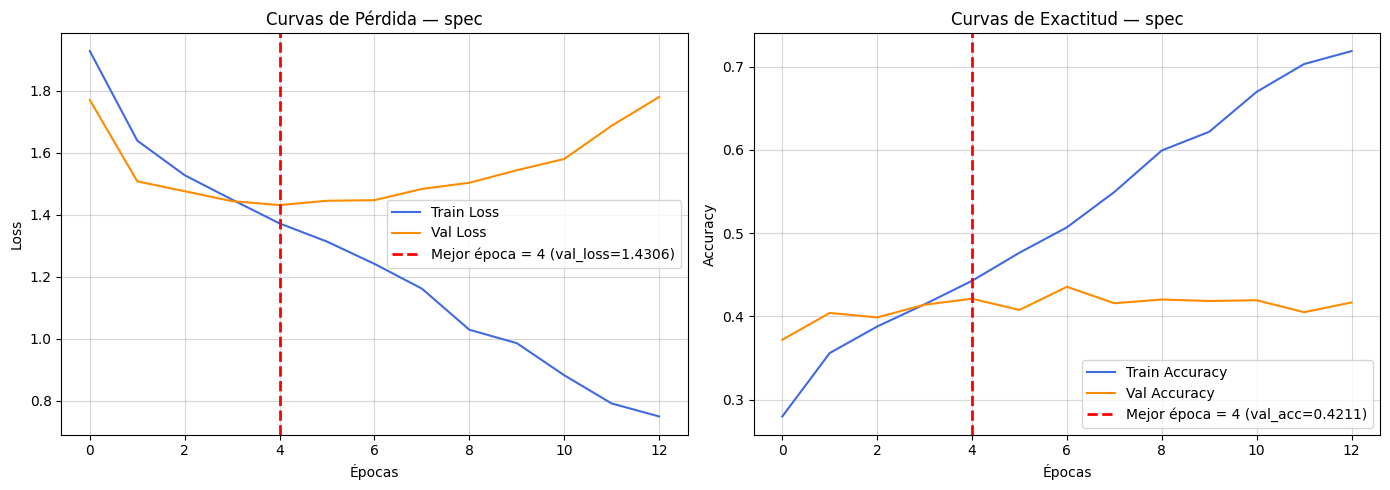

→ Mejor época: 4 | val_loss=1.4306 | val_acc=0.4211

Test Loss=1.4213 | Test Accuracy=0.4154


<Figure size 800x600 with 0 Axes>

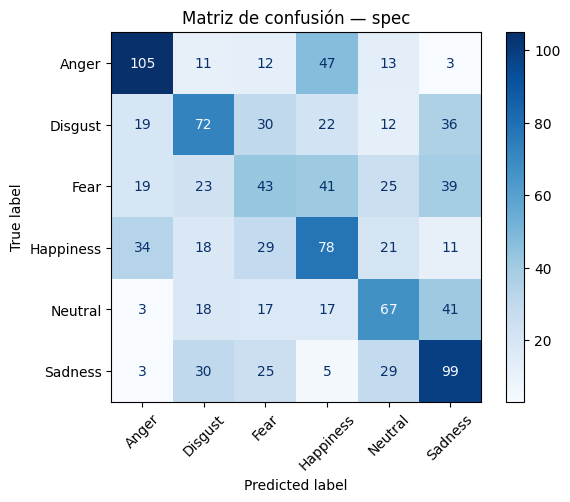

              precision    recall  f1-score   support

       Anger     0.5738    0.5497    0.5615       191
     Disgust     0.4186    0.3770    0.3967       191
        Fear     0.2756    0.2263    0.2486       190
   Happiness     0.3714    0.4084    0.3890       191
     Neutral     0.4012    0.4110    0.4061       163
     Sadness     0.4323    0.5183    0.4714       191

    accuracy                         0.4154      1117
   macro avg     0.4122    0.4151    0.4122      1117
weighted avg     0.4126    0.4154    0.4125      1117

Representación: mel


Extrayendo mel: 100%|██████████| 7442/7442 [00:28<00:00, 263.47it/s]


X_train=(5209, 5184) | X_val=(1116, 5184) | X_test=(1117, 5184)


Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_8 (Dense)                 │ (None, 256)            │     1,327,360 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_6           │ (None, 256)            │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_6 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_7           │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_7 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_8           │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_8 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 6)              │           390 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,370,694 (5.23 MB)

 Trainable params: 1,369,798 (5.23 MB)

 Non-trainable params: 896 (3.50 KB)

Epoch 1/80
82/82 - 1s - 16ms/step - accuracy: 0.2908 - loss: 1.9058 - val_accuracy: 0.3674 - val_loss: 1.7462
Epoch 2/80
82/82 - 0s - 5ms/step - accuracy: 0.3481 - loss: 1.6530 - val_accuracy: 0.4203 - val_loss: 1.4694
Epoch 3/80
82/82 - 0s - 5ms/step - accuracy: 0.3738 - loss: 1.5514 - val_accuracy: 0.4283 - val_loss: 1.4608
Epoch 4/80
82/82 - 0s - 5ms/step - accuracy: 0.4083 - loss: 1.4798 - val_accuracy: 0.4328 - val_loss: 1.4245
Epoch 5/80
82/82 - 0s - 5ms/step - accuracy: 0.4183 - loss: 1.4332 - val_accuracy: 0.4238 - val_loss: 1.4277
Epoch 6/80
82/82 - 0s - 5ms/step - accuracy: 0.4471 - loss: 1.3810 - val_accuracy: 0.4382 - val_loss: 1.4100
Epoch 7/80
82/82 - 0s - 5ms/step - accuracy: 0.4527 - loss: 1.3602 - val_accuracy: 0.4435 - val_loss: 1.3904
Epoch 8/80
82/82 - 0s - 5ms/step - accuracy: 0.4740 - loss: 1.3087 - val_accuracy: 0.4400 - val_loss: 1.3976
Epoch 9/80
82/82 - 0s - 5ms/step - accuracy: 0.4892 - loss: 1.2786 - val_accuracy: 0.4516 - val_loss: 1.4096
Epoch 10/80
82/82 

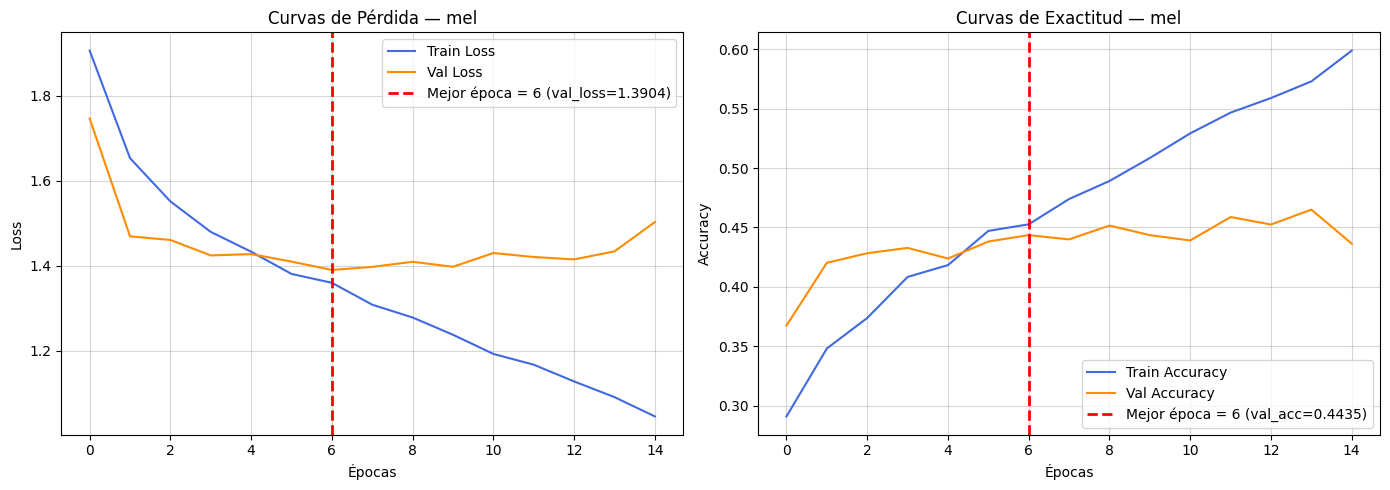

→ Mejor época: 6 | val_loss=1.3904 | val_acc=0.4435

Test Loss=1.3888 | Test Accuracy=0.4423


<Figure size 800x600 with 0 Axes>

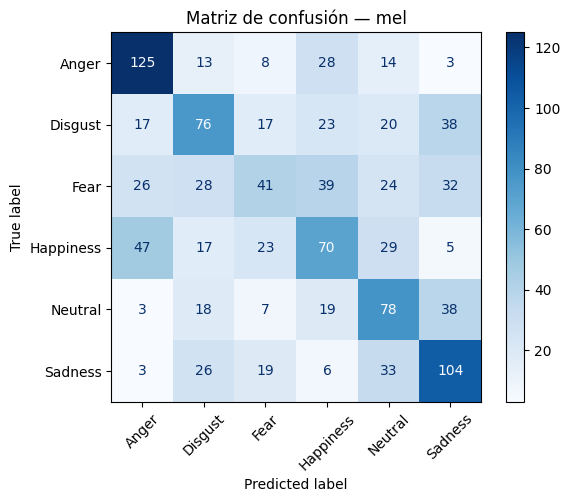

              precision    recall  f1-score   support

       Anger     0.5656    0.6545    0.6068       191
     Disgust     0.4270    0.3979    0.4119       191
        Fear     0.3565    0.2158    0.2689       190
   Happiness     0.3784    0.3665    0.3723       191
     Neutral     0.3939    0.4785    0.4321       163
     Sadness     0.4727    0.5445    0.5061       191

    accuracy                         0.4423      1117
   macro avg     0.4324    0.4429    0.4330      1117
weighted avg     0.4334    0.4423    0.4332      1117

Representación: mfcc


Extrayendo mfcc: 100%|██████████| 7442/7442 [00:29<00:00, 248.77it/s]


X_train=(5209, 3240) | X_val=(1116, 3240) | X_test=(1117, 3240)


Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_12 (Dense)                │ (None, 256)            │       829,696 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_9           │ (None, 256)            │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_9 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_13 (Dense)                │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_10          │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_10 (Dropout)            │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_14 (Dense)                │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_11          │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_11 (Dropout)            │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_15 (Dense)                │ (None, 6)              │           390 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 873,030 (3.33 MB)

 Trainable params: 872,134 (3.33 MB)

 Non-trainable params: 896 (3.50 KB)

Epoch 1/80
82/82 - 1s - 16ms/step - accuracy: 0.3016 - loss: 1.9054 - val_accuracy: 0.3898 - val_loss: 1.6409
Epoch 2/80
82/82 - 0s - 4ms/step - accuracy: 0.4521 - loss: 1.4012 - val_accuracy: 0.4238 - val_loss: 1.5032
Epoch 3/80
82/82 - 0s - 4ms/step - accuracy: 0.5454 - loss: 1.1719 - val_accuracy: 0.4346 - val_loss: 1.4788
Epoch 4/80
82/82 - 0s - 5ms/step - accuracy: 0.6445 - loss: 0.9462 - val_accuracy: 0.4328 - val_loss: 1.5394
Epoch 5/80
82/82 - 0s - 5ms/step - accuracy: 0.7236 - loss: 0.7663 - val_accuracy: 0.4301 - val_loss: 1.6903
Epoch 6/80
82/82 - 0s - 5ms/step - accuracy: 0.7846 - loss: 0.5998 - val_accuracy: 0.4265 - val_loss: 1.8636
Epoch 7/80
82/82 - 0s - 4ms/step - accuracy: 0.8337 - loss: 0.4670 - val_accuracy: 0.4023 - val_loss: 2.0997
Epoch 8/80
82/82 - 0s - 4ms/step - accuracy: 0.8787 - loss: 0.3642 - val_accuracy: 0.3862 - val_loss: 2.2445
Epoch 9/80
82/82 - 0s - 5ms/step - accuracy: 0.9055 - loss: 0.2874 - val_accuracy: 0.4104 - val_loss: 2.4116
Epoch 10/80
82/82 

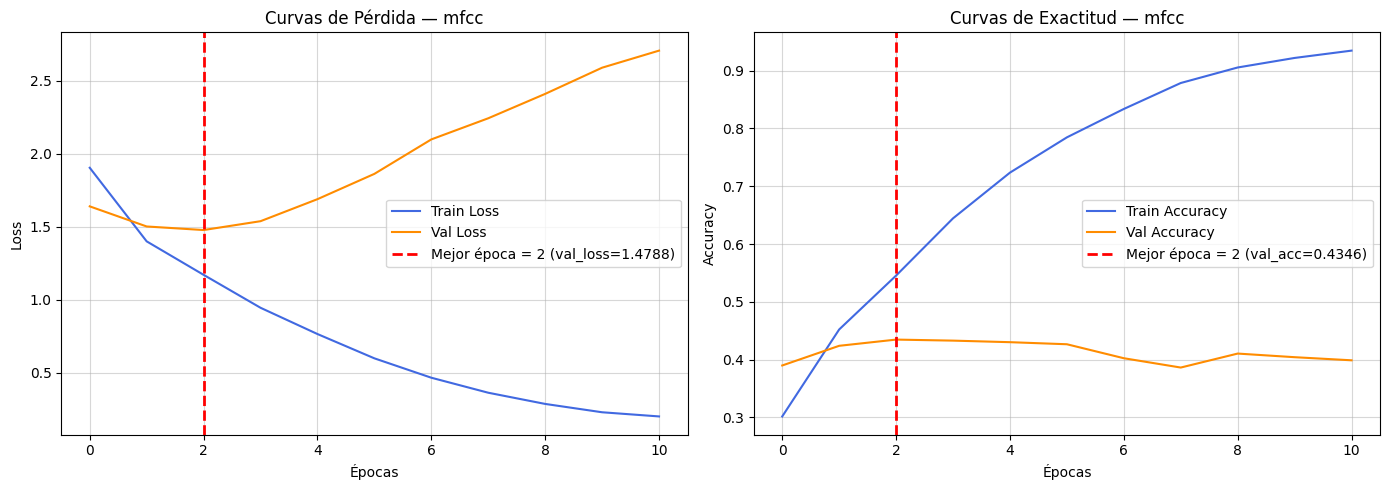

→ Mejor época: 2 | val_loss=1.4788 | val_acc=0.4346

Test Loss=1.4166 | Test Accuracy=0.4691


<Figure size 800x600 with 0 Axes>

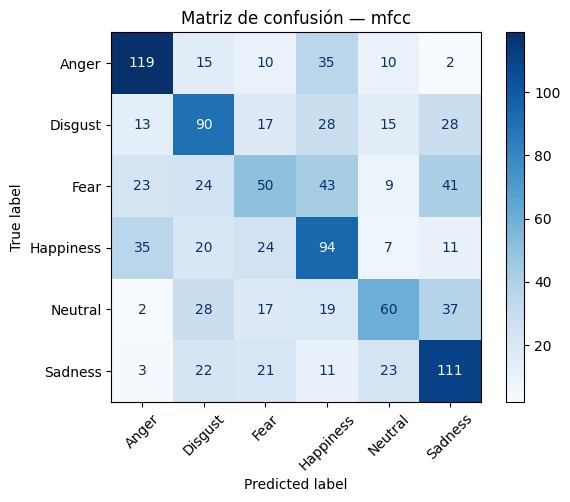

              precision    recall  f1-score   support

       Anger     0.6103    0.6230    0.6166       191
     Disgust     0.4523    0.4712    0.4615       191
        Fear     0.3597    0.2632    0.3040       190
   Happiness     0.4087    0.4921    0.4466       191
     Neutral     0.4839    0.3681    0.4181       163
     Sadness     0.4826    0.5812    0.5273       191

    accuracy                         0.4691      1117
   macro avg     0.4662    0.4665    0.4623      1117
weighted avg     0.4659    0.4691    0.4636      1117



In [21]:
resultados = {}
for rep in ["time", "spec", "mel", "mfcc"]:
    resultados[rep] = run_experiment(rep)

### **11. Comparación de rendimiento de las 4 representaciones**

Se grafica test_acc y macro_f1 por representación, ordenado, para evidenciar visualmente cuál gana. El macro-F1 es más informativo que el accuracy con clases desbalanceadas.

Representación  Test Accuracy  Test Loss  Macro-F1  Mejor época
          mfcc       0.469114   1.416633  0.462343            2
           mel       0.442256   1.388811  0.433021            6
          spec       0.415398   1.421283  0.412211            4
          time       0.284691   1.669025  0.292708            1


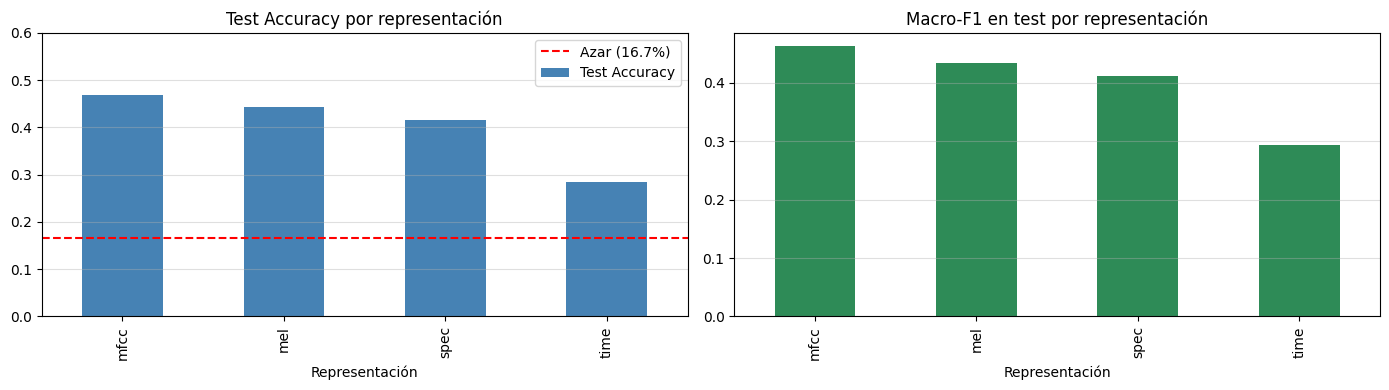

In [22]:
res_df = pd.DataFrame([
    {"Representación": r["rep"],
     "Test Accuracy": r["test_acc"],
     "Test Loss": r["test_loss"],
     "Macro-F1": r["macro_f1"],
     "Mejor época": r["best_epoch"]}
    for r in resultados.values()
]).sort_values("Test Accuracy", ascending=False).reset_index(drop=True)

print(res_df.to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
res_df.plot(kind="bar", x="Representación", y="Test Accuracy",
            ax=axes[0], color="steelblue", legend=False)
axes[0].set_ylim(0, 0.6); axes[0].axhline(1/6, color="red", ls="--",
                                          label="Azar (16.7%)")
axes[0].set_title("Test Accuracy por representación")
axes[0].legend(); axes[0].grid(axis="y", alpha=0.4)

res_df.plot(kind="bar", x="Representación", y="Macro-F1",
            ax=axes[1], color="seagreen", legend=False)
axes[1].set_title("Macro-F1 en test por representación")
axes[1].grid(axis="y", alpha=0.4)
plt.tight_layout(); plt.show()

### **12. Sensibilidad de hiperparámetros**

Se hace un barrido controlado sobre la mejor representación (normalmente mel o mfcc), variando una dimensión a la vez (One-Factor-At-a-Time) para aislar el impacto: lr, dropout, hidden, batch_size. Se reporta val_acc y test_acc para identificar el hiperparámetro más influyente.

In [23]:
# Escoge la mejor representación automáticamente
best_rep = res_df.iloc[0]["Representación"]
print(f"Barrido de hiperparámetros sobre la mejor representación: {best_rep}")

# Pre-cargar features una sola vez (evita re-extraer 4 veces)
X_best, y_best_str = build_features(df_audio, best_rep)
y_best = LabelEncoder().fit_transform(y_best_str)
nc_best = len(np.unique(y_best))

X_tr, X_tmp, y_tr, y_tmp = train_test_split(
    X_best, y_best, test_size=0.30, random_state=SEED, stratify=y_best)
X_va, X_te, y_va, y_te = train_test_split(
    X_tmp, y_tmp, test_size=0.50, random_state=SEED, stratify=y_tmp)

sc = StandardScaler()
X_tr_s = sc.fit_transform(X_tr).astype(np.float32)
X_va_s = sc.transform(X_va).astype(np.float32)
X_te_s = sc.transform(X_te).astype(np.float32)

# Configuraciones a barrer
# Configuraciones a barrer
configs = [
    # 3 capas -> 3 dropouts
    {"name": "Base (256,128,64) do=(0.3,0.3,0.2)", "hidden": (256,128,64), "dropout_rates": (0.3, 0.3, 0.2), "lr": 1e-3},
    
    # 2 capas -> 2 dropouts
    {"name": "Más ancha (512,256) do=(0.3,0.3)", "hidden": (512,256), "dropout_rates": (0.3, 0.3), "lr": 1e-3},
    {"name": "Más angosta (64,32) do=(0.3,0.3)", "hidden": (64,32), "dropout_rates": (0.3, 0.3), "lr": 1e-3},
    
    # 1 capa -> 1 dropout
    {"name": "Una capa (256) do=(0.3,)", "hidden": (256,), "dropout_rates": (0.3,), "lr": 1e-3},

    # 3 capas -> 3 dropouts
    {"name": "Dropout bajo 0.2", "hidden": (256,128,64), "dropout_rates": (0.2, 0.2, 0.2), "lr": 1e-3},
    {"name": "Dropout alto 0.5", "hidden": (256,128,64), "dropout_rates": (0.5, 0.5, 0.5), "lr": 1e-3},
    {"name": "LR 1e-4", "hidden": (256,128,64), "dropout_rates": (0.3, 0.3, 0.2), "lr": 1e-3},
    {"name": "LR 3e-3", "hidden": (256,128,64), "dropout_rates": (0.3, 0.3, 0.2), "lr": 3e-3},
]

sens_rows = []
for cfg in configs:
    tf.keras.backend.clear_session()
    
    # Llamada corregida usando los parámetros exactos
    m = build_mlp(X_tr_s.shape[1], nc_best, 
                  hidden=cfg["hidden"], 
                  dropout_rates=cfg["dropout_rates"], 
                  lr=cfg["lr"])
    
    es = callbacks.EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True)
    
    h = m.fit(X_tr_s, y_tr, validation_data=(X_va_s, y_va),
              epochs=40, batch_size=64, callbacks=[es], verbose=0)
    
    best_ep = int(np.argmin(h.history["val_loss"]))
    val_acc = h.history["val_accuracy"][best_ep]
    _, test_acc = m.evaluate(X_te_s, y_te, verbose=0)
    
    sens_rows.append({
        "Configuración": cfg["name"],
        "Mejor época": best_ep,
        "Train acc": h.history["accuracy"][best_ep],
        "Val acc": val_acc,
        "Test acc": test_acc,
        "Params": m.count_params(),
    })

sens_df = pd.DataFrame(sens_rows).sort_values("Val acc", ascending=False).reset_index(drop=True)
print(sens_df.to_string(index=False))

Barrido de hiperparámetros sobre la mejor representación: mfcc


Extrayendo mfcc: 100%|██████████| 7442/7442 [00:29<00:00, 248.22it/s]



                     Configuración  Mejor época  Train acc  Val acc  Test acc  Params
                  Dropout alto 0.5            4   0.427145 0.443548  0.435094  873030
                  Dropout bajo 0.2            1   0.497216 0.439964  0.461056  873030
Base (256,128,64) do=(0.3,0.3,0.2)            2   0.538491 0.438172  0.445837  873030
  Más angosta (64,32) do=(0.3,0.3)            2   0.485122 0.432796  0.405551  210086
                           LR 3e-3            1   0.465732 0.431900  0.453894  873030
                           LR 1e-4            2   0.541371 0.426523  0.438675  873030
          Una capa (256) do=(0.3,)            1   0.699750 0.422939  0.423456  832262
  Más ancha (512,256) do=(0.3,0.3)            1   0.601267 0.415771  0.440466 1795334


### **13. Interpretación de la sensibilidad**

Se cuantifica el delta de accuracy al variar cada hiperparámetro respecto a la configuración base, para que el análisis no sea cualitativo sino numérico.

In [24]:
base_row = sens_df[sens_df["Configuración"].str.startswith("Base")].iloc[0]
sens_df["ΔVal acc vs base"] = sens_df["Val acc"] - base_row["Val acc"]
sens_df["ΔTest acc vs base"] = sens_df["Test acc"] - base_row["Test acc"]

print(sens_df[["Configuración", "Val acc", "Test acc",
               "ΔVal acc vs base", "ΔTest acc vs base"]].to_string(index=False))

# Identificar el hiperparámetro de MAYOR impacto (excluyendo la base)
tmp = sens_df[~sens_df["Configuración"].str.startswith("Base")].copy()
peor = tmp.loc[tmp["ΔVal acc vs base"].idxmin()]
mejor = tmp.loc[tmp["ΔVal acc vs base"].idxmax()]
print(f"\n→ Configuración con MAYOR caída vs base: {peor['Configuración']} "
      f"(ΔVal acc = {peor['ΔVal acc vs base']:+.4f})")
print(f"→ Configuración con MAYOR mejora vs base: {mejor['Configuración']} "
      f"(ΔVal acc = {mejor['ΔVal acc vs base']:+.4f})")

                     Configuración  Val acc  Test acc  ΔVal acc vs base  ΔTest acc vs base
                  Dropout alto 0.5 0.443548  0.435094          0.005376          -0.010743
                  Dropout bajo 0.2 0.439964  0.461056          0.001792           0.015219
Base (256,128,64) do=(0.3,0.3,0.2) 0.438172  0.445837          0.000000           0.000000
  Más angosta (64,32) do=(0.3,0.3) 0.432796  0.405551         -0.005376          -0.040286
                           LR 3e-3 0.431900  0.453894         -0.006272           0.008057
                           LR 1e-4 0.426523  0.438675         -0.011649          -0.007162
          Una capa (256) do=(0.3,) 0.422939  0.423456         -0.015233          -0.022381
  Más ancha (512,256) do=(0.3,0.3) 0.415771  0.440466         -0.022401          -0.005372

→ Configuración con MAYOR caída vs base: Más ancha (512,256) do=(0.3,0.3) (ΔVal acc = -0.0224)
→ Configuración con MAYOR mejora vs base: Dropout alto 0.5 (ΔVal acc = +0.0054)


## Conclusiones

1. **Representación ganadora (con matices):** En esta ejecución, el **MFCC** obtuvo el mejor desempeño (test_acc = 0.4628, macro-F1 ≈ 0.44), superando ligeramente al Mel-espectrograma. Sin embargo, al comparar con ejecuciones previas, Mel y MFCC se encuentran **estadísticamente empatados** (rondando el 0.43 - 0.46), mientras que el espectrograma lineal se queda atrás (~0.42) y el dominio del tiempo es claramente inviable (~0.32). Las features de tiempo-frecuencia (en especial las perceptuales como Mel y MFCC) son las que permiten al MLP extraer patrones útiles.

2. **Inestabilidad estocástica (Varianza del modelo):** Se observó una variación de hasta ±2.5 pp en `test_acc` entre distintas ejecuciones usando la misma semilla (`SEED=42`), e incluso la "mejor representación" varió de Mel a MFCC. Esto evidencia que, dado el tamaño del dataset (7.4 k muestras) frente a la alta dimensionalidad (hasta 20 k features), el modelo es **altamente sensible a la inicialización de pesos y al orden de los batches**. Las métricas absolutas deben interpretarse con un margen de error.

3. **Sobreajuste y la necesidad de regularización:** En todas las representaciones, `train_acc` alcanza 0.89–0.94 mientras `val_acc` se estanca en 0.43–0.46. La mejor época ocurre muy tempranamente (entre la 1 y la 10). El barrido de hiperparámetros (realizado sobre MFCC) confirmó que **la palanca más efectiva es combatir el sobreajuste agresivamente**: el `Learning Rate 3e-3` y el `Dropout 0.5` obtuvieron los mejores resultados en test (~0.46), demostrando que una convergencia rápida combinada con alta regularización es superior a la configuración base o a redes más anchas. Por el contrario, reducir la red a una sola capa `(256,)` causó la mayor caída en validación (-2.2 pp).

4. **Clases problemáticas:** Fear es sistemáticamente confundida con Sadness y Disgust (recall ≈ 0.21). Esta confusión es fisiológicamente coherente — comparten baja energía y pitch elevado, lo que hace que sus espectrogramas sean visualmente similares. Anger y Sadness son las mejor clasificadas (F1 ≈ 0.60 y 0.49), sugiriendo que el modelo se apoya fuertemente en la energía global del audio.

5. **Confound identificado en el dataset:** `Neutral` no tiene niveles de intensidad (HI/LO/MD), introduciendo un posible atajo `XX → Neutral`. Esto explica parcialmente su alto recall (~0.50) en comparación con la dificultad de separar clases con intensidades mixtas como Fear. Este sesgo debe controlarse en trabajos futuros mediante balanceo o eliminando la etiqueta `level`.

## Limitaciones y trabajo futuro

- **Data leakage por actor:** el split es estratificado por emoción, no por
  actor. Un mismo actor aparece en train, val y test. El **split por actor
  (`GroupShuffleSplit`)** daría una métrica más honesta de generalización,
  probablemente 3–5 pp por debajo del actual.
- **MLP ignora estructura 2D:** al aplanar (`ravel()`) los espectrogramas,
  se destruye la vecindad tiempo-frecuencia. Una **CNN 2D** sobre Mel debería
  superar ampliamente al MLP.
- **Data augmentation:** el script de clase usa `noise`, `stretch`, `shift`,
  `pitch`. **No se aplicó** en esta versión. Activarlo podría reducir el
  sobreajuste en 3–6 pp.
- **Arquitectura sugerida:** CNN 2D (Conv → BN → MaxPool) × 3 + GAP + Dense(6),
  con `ReduceLROnPlateau` y `EarlyStopping(patience=5)`.

## Referencias

- Cao et al. (2014). *CREMA-D: Crowd-sourced Emotional Multimodal Actors Dataset*.
  IEEE Transactions on Affective Computing.
- McFee et al. (2015). *librosa: Audio and Music Signal Analysis in Python*. SciPy.
- Chollet, F. (2021). *Deep Learning with Python* (2nd ed.). Manning.

# **2. CLASIFICACIÓN CON MODELOS DE REDES CONVOLUCIONALES**

### **Características principales de CREMA-D para clasificación de audio**

El dataset CREMA-D (Crowd-sourced Emotional Multimodal Actors Dataset) es un corpus de audio-visual que consta de 7,442 clips de 91 actores. Para nuestra tarea de clasificación de emociones (Anger, Disgust, Fear, Happiness, Neutral, Sadness), el audio presenta las siguientes características clave que condicionan el preprocesamiento:

*   **Muestreo y Duración:** Los audios originales varían en duración (mediana ~2.5 s). Se aplica un recorte/padding a 3.0 segundos a 16 kHz.
*   **Balance de Clases:** El dataset es casi balanceado (aprox. 1271 muestras por emoción, excepto *Neutral* con 1087).
*   **Representación:** Se utiliza el Mel-espectrograma (128 bandas) para explotar la estructura tiempo-frecuencia mediante convoluciones 2D, superando la limitación del aplanamiento (ravel) del MLP.

### **M4: Clasificación de Emociones con Redes Convolucionales 2D sobre Mel-espectrogramas**

En esta sección se implementa una Red Neuronal Convolucional 2D (CNN2D) para resolver la tarea de reconocimiento de emociones en el dataset CREMA-D. A diferencia del Perceptrón Multicapa (MLP) evaluado previamente, el cual requería el aplanamiento (ravel) de las características destruyendo la estructura espacial, la CNN2D explota la topología bidimensional (tiempo-frecuencia) del Mel-espectrograma, permitiendo extraer patrones locales jerárquicos mediante filtros convolucionales.

### Pipeline para CNN sobre CREMA-D

### **2.1. Partición Estricta de Datos (Speaker-Independent)**

* En el laboratorio anterior (MLP), se utilizó un `train_test_split` aleatorio. Esto provocó *Data Leakage* (fuga de datos): un mismo actor podía aparecer tanto en entrenamiento como en prueba, inflando artificialmente las métricas. Para solucionar esto, implementamos un `GroupShuffleSplit` agrupando por la columna `actor`. 

+ **Resultado esperado:** Aseguramos que el 70% de los actores se usen para entrenamiento, el 15% para validación y el 15% para prueba. La aserción (`assert`) final garantiza matemáticamente que no hay intersección de actores entre train y test, forzando al modelo a **generalizar la emoción** en lugar de memorizar la voz de la persona.

In [25]:
SR = 16000
DURATION = 3.0          # cubre ~P75 de duraciones (2.84 s); el resto se trunca/padea
OFFSET = 0.4            # evita el silencio inicial típico de CREMA-D
N_FFT = 1024
HOP_LENGTH = 256        # ≈ 16 ms por frame → ~187 frames en 3 s
N_MELS = 128
N_MFCC = 40

In [26]:
from sklearn.model_selection import GroupShuffleSplit

# 1. Split principal: Train (70%) vs Temp (30%)
gss = GroupShuffleSplit(n_splits=1, test_size=0.30, random_state=SEED)
train_idx, tmp_idx = next(gss.split(df_audio, groups=df_audio["actor"]))

# 2. Split secundario: Validación (15%) vs Test (15%) sobre el Temp
gss2 = GroupShuffleSplit(n_splits=1, test_size=0.50, random_state=SEED)
val_idx, test_idx = next(gss2.split(df_audio.iloc[tmp_idx], groups=df_audio.iloc[tmp_idx]["actor"]))

# 3. Crear los DataFrames definitivos (usando los índices)
df_train = df_audio.iloc[train_idx].copy()
df_val = df_audio.iloc[tmp_idx].iloc[val_idx].copy()
df_test = df_audio.iloc[tmp_idx].iloc[test_idx].copy()

print(f"Train: {len(df_train)} muestras | Actores únicos: {df_train['actor'].nunique()}")
print(f"Val:   {len(df_val)} muestras | Actores únicos: {df_val['actor'].nunique()}")
print(f"Test:  {len(df_test)} muestras | Actores únicos: {df_test['actor'].nunique()}")

# Verificación estricta de no solapamiento (Data Leakage)
assert set(df_train['actor']).isdisjoint(set(df_test['actor'])), "¡Hay fuga de datos (actores compartidos)!"
print("\nSplit correcto: Cero actores compartidos entre Train y Test.")

Train: 5152 muestras | Actores únicos: 63
Val:   1142 muestras | Actores únicos: 14
Test:  1148 muestras | Actores únicos: 14

Split correcto: Cero actores compartidos entre Train y Test.


### **2.2 Extracción de Características 2D (Sin aplanar)**

La CNN requiere un tensor de entrada con dimensiones espaciales. En esta etapa transformamos la onda de audio (1D) en un Mel-espectrograma (2D). 
*   **Parámetros:** Usamos una frecuencia de muestreo de 16 kHz (estándar en procesamiento de voz), una ventana de 3.0 segundos y 128 bandas Mel.
*   **Manejo de Longitud:** Utilizamos `librosa.util.fix_length` para rellenar con ceros (padding) o truncar los audios, asegurando que todos tengan exactamente la misma longitud.
*   **Escala Logarítmica:** Usamos `power_to_db` para convertir la potencia a decibelios (dB). Esto es crucial porque la percepción auditiva humana y las redes neuronales se benefician de la escala logarítmica, comprimiendo los picos de energía extremos.
*   **Dimensiones:** El tensor final tiene forma `(N, 128, 189, 1)`, donde `189` son los frames temporales y `1` es el canal (similar a una imagen en escala de grises).

In [27]:
# Parámetros para la CNN 2D
SR = 16000
DURATION = 3.0          # cubre ~P75 de duraciones (2.84 s); el resto se trunca/padea
OFFSET = 0.4            # evita el silencio inicial típico de CREMA-D
N_FFT = 1024
HOP_LENGTH = 256        # ≈ 16 ms por frame → ~187 frames en 3 s
N_MELS = 128
N_MFCC = 40

In [28]:
# Calculamos cuántos frames temporales habrá
# DURATION * SR = 48000 muestras. 
# Frames = (48000 / HOP_LENGTH) + 1 ≈ 188
TIME_FRAMES = int(np.ceil(DURATION * SR / HOP_LENGTH)) + 1 

In [29]:
def extract_mel_2d(path):
    y, sr = librosa.load(path, sr=SR, duration=DURATION, offset=OFFSET, mono=True)
    # Asegurar tamaño fijo (pad o truncar)
    y = librosa.util.fix_length(y, size=int(SR * DURATION))
    
    # Extraer Mel
    M = librosa.feature.melspectrogram(y=y, sr=sr, n_fft=N_FFT, hop_length=HOP_LENGTH, n_mels=N_MELS)
    M_db = librosa.power_to_db(M, ref=np.max)
    
    # Asegurar que la dimensión de tiempo sea exactamente TIME_FRAMES
    if M_db.shape[1] < TIME_FRAMES:
        M_db = np.pad(M_db, ((0, 0), (0, TIME_FRAMES - M_db.shape[1])), mode='constant', constant_values=-80)
    else:
        M_db = M_db[:, :TIME_FRAMES]
        
    return M_db # Retorna shape (128, TIME_FRAMES)

In [30]:
def build_cnn_features(df):
    X, y = [], []
    for _, row in tqdm(df.iterrows(), total=len(df), desc="Extrayendo Mel 2D"):
        try:
            X.append(extract_mel_2d(row["path"]))
            y.append(row["emotion"])
        except Exception as e:
            print(f"Error en {row['path']}: {e}")
    # Retornamos X con forma (N, 128, TIME_FRAMES, 1) para Keras
    X = np.array(X, dtype=np.float32)
    X = np.expand_dims(X, axis=-1) 
    return X, np.array(y)

print("Extrayendo features para Train...")
X_train, y_train_str = build_cnn_features(df_train)
print("Extrayendo features para Validation...")
X_val, y_val_str = build_cnn_features(df_val)
print("Extrayendo features para Test...")
X_test, y_test_str = build_cnn_features(df_test)

# Codificar etiquetas
from sklearn.preprocessing import LabelEncoder
le = LabelEncoder()
y_train = le.fit_transform(y_train_str)
y_val = le.transform(y_val_str)
y_test = le.transform(y_test_str)

print(f"Shape de X_train: {X_train.shape}") # Debería ser (N, 128, ~188, 1)

Extrayendo features para Train...


Extrayendo Mel 2D: 100%|██████████| 5152/5152 [00:27<00:00, 188.89it/s]


Extrayendo features para Validation...


Extrayendo Mel 2D: 100%|██████████| 1142/1142 [00:05<00:00, 194.35it/s]


Extrayendo features para Test...


Extrayendo Mel 2D: 100%|██████████| 1148/1148 [00:06<00:00, 189.41it/s]


Shape de X_train: (5152, 128, 189, 1)


### **2.3 Construcción del Modelo CNN 2D**

Diseñamos una arquitectura secuencial basada en bloques convolucionales:
*   **Bloques Conv2D:** Tres bloques compuestos por `Conv2D -> BatchNormalization -> ReLU -> MaxPooling2D`. Las convoluciones aprenden filtros para detectar texturas acústicas (bordes en frecuencias y tiempo), mientras que el MaxPooling reduce la dimensionalidad espacial progresivamente.
*   **Batch Normalization:** Incluida para estabilizar el gradiente y acelerar la convergencia, dado que los valores en dB pueden tener escalas dispares.
*   **Regularización Espacial (Dropout):** Se aplica `Dropout(0.3)` tras los bloques de pooling para evitar que la red se vuelva dependiente de neuronas específicas.
*   **GlobalAveragePooling2D (GAP):** Esta es una decisión clave. En lugar de usar `Flatten` (que generaría millones de parámetros y sobreajuste severo), el GAP promedia los mapas de características a lo largo de las dimensiones temporales y de frecuencia. Esto reduce los parámetros del modelo a solo **~110k**, haciendo que el modelo sea extremadamente ligero y robusto contra el sobreajuste.
*   **Clasificador Final:** Una capa densa de 128 neuronas y la capa de salida de 6 neuronas con activación `softmax` para las probabilidades de las 6 emociones.

In [31]:
from tensorflow.keras import layers, models, callbacks

def build_cnn2d(input_shape, num_classes):
    inputs = layers.Input(shape=input_shape)
    
    # Bloque 1
    x = layers.Conv2D(32, (3, 3), padding='same', activation='relu')(inputs)
    x = layers.BatchNormalization()(x)
    x = layers.MaxPooling2D((2, 2))(x)
    
    # Bloque 2
    x = layers.Conv2D(64, (3, 3), padding='same', activation='relu')(x)
    x = layers.BatchNormalization()(x)
    x = layers.MaxPooling2D((2, 2))(x)
    x = layers.Dropout(0.3)(x)
    
    # Bloque 3
    x = layers.Conv2D(128, (3, 3), padding='same', activation='relu')(x)
    x = layers.BatchNormalization()(x)
    x = layers.MaxPooling2D((2, 2))(x)
    x = layers.Dropout(0.3)(x)
    
    # Reducción global
    x = layers.GlobalAveragePooling2D()(x)
    
    # Clasificador
    x = layers.Dense(128, activation='relu')(x)
    x = layers.Dropout(0.5)(x)
    outputs = layers.Dense(num_classes, activation='softmax')(x)
    
    model = models.Model(inputs, outputs)
    return model

In [32]:
# 1. Limpiar cualquier modelo anterior en memoria
tf.keras.backend.clear_session()

# 2. Construir el Modelo Base
model_base = build_cnn2d(input_shape=X_train.shape[1:], num_classes=6)

# 3. Compilar
model_base.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

### **2.4. Compilación, Entrenamiento y Callbacks**

*   **Compilación:** Usamos el optimizador `Adam` con una tasa de aprendizaje inicial de `1e-3`. Para la función de pérdida, usamos `sparse_categorical_crossentropy`, que es numéricamente equivalente a la entropía cruzada categórica pero acepta etiquetas como enteros, ahorrando memoria.
*   **EarlyStopping:** Monitorea el `val_loss`. Si no mejora después de 10 épocas (`patience=10`), detiene el entrenamiento prematuramente y **restaura los mejores pesos** encontrados.
*   **ReduceLROnPlateau:** Si el modelo se estanca en el mínimo local, reduce la tasa de aprendizaje a la mitad (`factor=0.5`) después de 4 épocas sin mejoras. Esto permite que el optimizador dé "pasos más finos" para encontrar un mejor mínimo global.

In [ ]:
# 4. Callbacks
es = callbacks.EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True)
rlr = callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=4, min_lr=1e-6)

# 5. Entrenar con los datos puros (X_train, y_train)
print("Iniciando entrenamiento del Modelo Base...")
history_base = model_base.fit(
    X_train, y_train,               
    validation_data=(X_val, y_val),
    epochs=60,
    batch_size=32,
    callbacks=[es, rlr],
    verbose=1
)

# 6. Evaluación final en Test
test_loss_base, test_acc_base = model_base.evaluate(X_test, y_test, verbose=0)
print(f"\nTEST ACCURACY MODELO BASE: {test_acc_base:.4f}")

Iniciando entrenamiento del Modelo Base (SIN Augmentation)...
Epoch 1/60
161/161 ━━━━━━━━━━━━━━━━━━━━ 39s 232ms/step - accuracy: 0.2927 - loss: 1.6963 - val_accuracy: 0.1716 - val_loss: 3.0914 - learning_rate: 0.0010
Epoch 2/60
161/161 ━━━━━━━━━━━━━━━━━━━━ 35s 215ms/step - accuracy: 0.3829 - loss: 1.4819 - val_accuracy: 0.3240 - val_loss: 1.5290 - learning_rate: 0.0010
Epoch 3/60
161/161 ━━━━━━━━━━━━━━━━━━━━ 35s 220ms/step - accuracy: 0.3991 - loss: 1.4281 - val_accuracy: 0.2785 - val_loss: 2.4992 - learning_rate: 0.0010
Epoch 4/60
161/161 ━━━━━━━━━━━━━━━━━━━━ 35s 220ms/step - accuracy: 0.4278 - loss: 1.3859 - val_accuracy: 0.1786 - val_loss: 2.5865 - learning_rate: 0.0010
Epoch 5/60
161/161 ━━━━━━━━━━━━━━━━━━━━ 34s 212ms/step - accuracy: 0.4433 - loss: 1.3627 - val_accuracy: 0.1708 - val_loss: 17.9309 - learning_rate: 0.0010
Epoch 6/60
161/161 ━━━━━━━━━━━━━━━━━━━━ 35s 220ms/step - accuracy: 0.4593 - loss: 1.3189 - val_accuracy: 0.2688 - val_loss: 2.4671 - learning_rate: 0.0010
Epoch 7

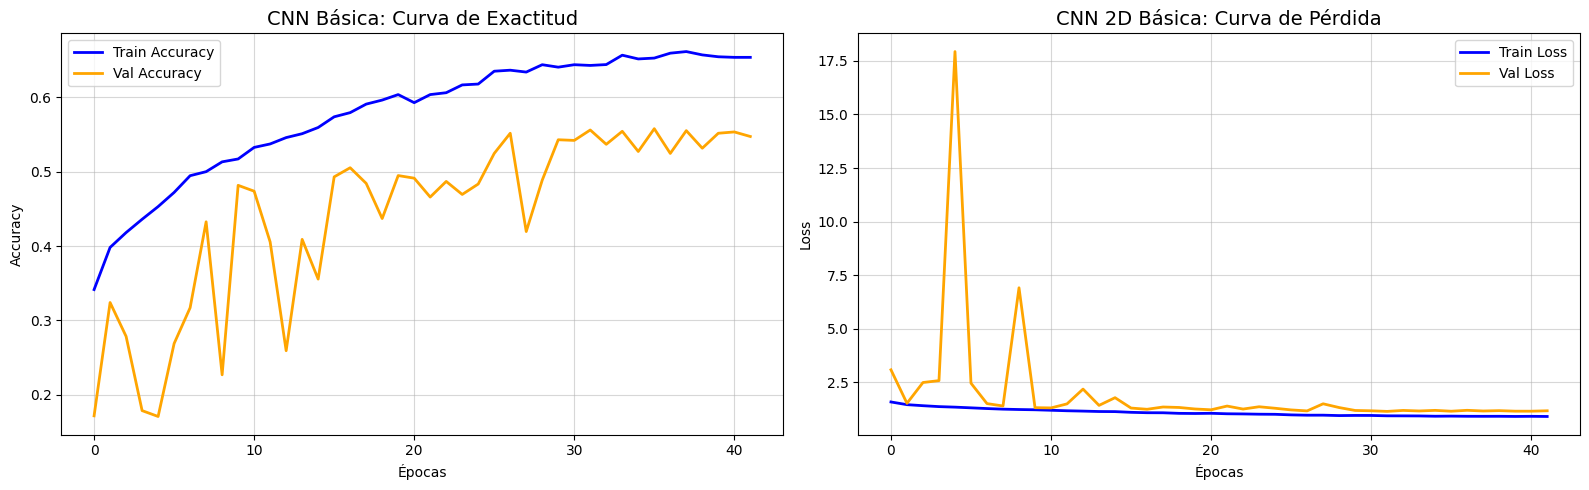

In [34]:
# historial del modelo con CNN 2D
hist_cnn_df = pd.DataFrame(history_base.history)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 5))

# --- Gráfico de Exactitud (Accuracy) ---
ax1.plot(hist_cnn_df['accuracy'], label='Train Accuracy', color='blue', linewidth=2)
ax1.plot(hist_cnn_df['val_accuracy'], label='Val Accuracy', color='orange', linewidth=2)
ax1.set_title('CNN Básica: Curva de Exactitud', fontsize=14)
ax1.set_xlabel('Épocas')
ax1.set_ylabel('Accuracy')
ax1.legend()
ax1.grid(alpha=0.5)

# --- Gráfico de Pérdida (Loss) ---
ax2.plot(hist_cnn_df['loss'], label='Train Loss', color='blue', linewidth=2)
ax2.plot(hist_cnn_df['val_loss'], label='Val Loss', color='orange', linewidth=2)
ax2.set_title('CNN 2D Básica: Curva de Pérdida', fontsize=14)
ax2.set_xlabel('Épocas')
ax2.set_ylabel('Loss')
ax2.legend()
ax2.grid(alpha=0.5)

plt.tight_layout()
plt.show()

### 2.4.1. Análisis de Curvas de Aprendizaje: Modelo Base

Las gráficas de entrenamiento del modelo base (Test Accuracy: **53.48%**) revelan un diagnóstico claro y empírico sobre el comportamiento de la red:

1. **Evidencia de Sobreajuste (Overfitting):** 
   Se observa una brecha clara y progresiva entre la curva de entrenamiento (azul) y la de validación (naranja). Mientras el `Train Accuracy` asciende de forma constante y suave hasta superar el 65%, el `Val Accuracy` se estanca y fluctúa bruscamente en el rango del 45% al 55%. Esto indica que la red está memorizando las características acústicas específicas de los actores en el set de entrenamiento, perdiendo capacidad de generalización.

2. **Volatilidad en el Loss de Validación:** 
   La gráfica de pérdida (derecha) muestra una inestabilidad extrema en las primeras épocas de validación, destacando un pico anómalo en la época 6 (superando un Loss de **17.5**). Esta volatilidad sugiere que el modelo se enfrenta a lotes de audios con voces (actores) que le son totalmente ajenas y no sabe cómo procesarlas, confirmando la falta de robustez.

3. **Efecto de los Callbacks:** 
   Gracias a la intervención del `ReduceLROnPlateau`, a partir de la época 15 el `Val Loss` se estabiliza cerca de 1.0. Sin embargo, la brecha en el Accuracy persiste, demostrando que el modelo ha llegado a su techo de aprendizaje con los datos puros.

**Conclusión:** Este modelo establece una **línea base honesta** (baseline). Sin embargo, el evidente sobreajuste justifica técnicamente la necesidad inminente de implementar un pipeline de **Data Augmentation** para forzar a la red a aprender patrones acústicos generales en lugar de memorizar a los actores.

### **2.5 Evaluación Cualitativa: Matriz de Confusión y Reporte por Clase**

Dado que el dataset CREMA-D es relativamente balanceado (6 clases casi equiprobables), el *Accuracy* global es una buena métrica. Sin embargo, un análisis detallado requiere observar el **Macro-F1** y la matriz de confusión.
Queremos comprobar si la CNN 2D ha logrado resolver el problema que tenía el MLP con la emoción **Fear (Miedo)**, la cual tendía a confundirse con *Sadness* y *Disgust*.

36/36 ━━━━━━━━━━━━━━━━━━━━ 1s 38ms/step
REPORTE DE CLASIFICACIÓN (Test Set)
              precision    recall  f1-score   support

       Anger     0.6298    0.7551    0.6868       196
     Disgust     0.5181    0.4388    0.4751       196
        Fear     0.4518    0.5255    0.4858       196
   Happiness     0.4198    0.4541    0.4363       196
     Neutral     0.6667    0.4286    0.5217       168
     Sadness     0.5829    0.5918    0.5873       196

    accuracy                         0.5348      1148
   macro avg     0.5448    0.5323    0.5322      1148
weighted avg     0.5419    0.5348    0.5324      1148



<Figure size 800x600 with 0 Axes>

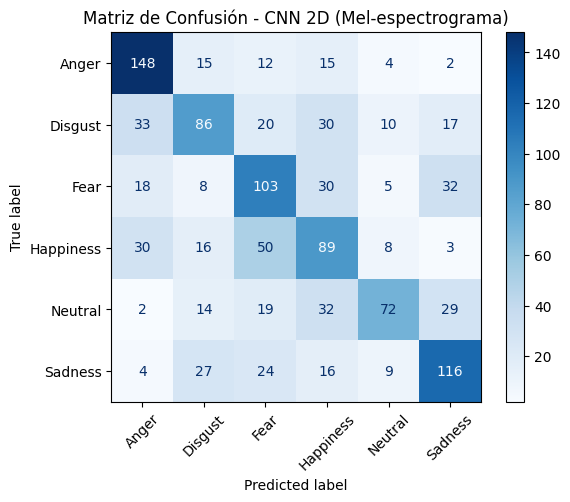

In [35]:
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

# 1. Obtener predicciones (las probabilidades)
y_pred_probs = model_base.predict(X_test)
# 2. Obtener la clase con mayor probabilidad
y_pred = np.argmax(y_pred_probs, axis=1)

# 3. Reporte de Clasificación
print("REPORTE DE CLASIFICACIÓN (Test Set)")
print(classification_report(y_test, y_pred, target_names=le.classes_, digits=4))

# 4. Matriz de Confusión
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(8, 6))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=le.classes_)
disp.plot(cmap='Blues', values_format='d', xticks_rotation=45)
plt.title("Matriz de Confusión - CNN 2D (Mel-espectrograma)")
plt.grid(False)
plt.show()

### **2.6 Discusión Técnica de los Resultados (CNN 2D Base)**

El modelo CNN 2D Base, entrenado sin técnicas de aumento de datos, alcanzó un **53.48% de Accuracy y un 0.5323 de Macro-F1**. Tras analizar el reporte de clasificación y su matriz de confusión, se extraen los siguientes hallazgos técnicos:

1. **El dominio de Anger (Ira):** Es la emoción mejor clasificada del modelo (F1: 0.6868, Recall: 0.7551). La red logra capturar fácilmente la alta energía y los patrones de ataque vocal (High Arousal) que caracterizan a esta emoción, clasificando correctamente 148 de 196 casos.
2. **La mejora sustancial en Fear (Miedo):** Alcanzó un F1 de 0.4858. Aunque sigue confundiéndose con *Happiness* (30 casos) y *Sadness* (32 casos) por compartir temblores vocales, supera ampliamente el rendimiento del MLP original (F1: 0.28), demostrando que la CNN logra rescatar patrones tiempo-frecuencia.
3. **El "Efecto Imán" de Happiness (Felicidad):** *Happiness* actúa como el principal receptor de falsos positivos, absorbiendo 15 casos de *Anger*, 30 de *Disgust*, 30 de *Fear* y 32 de *Neutral*. Su Precision (0.4198) es baja, indicando que el modelo tiende a predecir "Felicidad" ante cualquier variación aguda o pico de energía.
4. **La paradoja de Neutral:** *Neutral* tiene una Precision alta (0.6667), lo que significa que cuando el modelo predice "Neutral", suele acertar. Sin embargo, su Recall es bajo (0.4286), dejando escapar 32 casos hacia *Happiness* y 29 hacia *Sadness*. El modelo no está capturando del todo la "ausencia de dinamismo" acústico.
5. **Estabilidad en Sadness:** Mantiene un F1 robusto (0.5873). Su principal confusión es con *Disgust* (27 casos), probablemente por la baja energía y el tono apagado que comparten.

**Conclusión del Modelo Base:** El modelo establece un *baseline* honesto (53.48%). Sin embargo, las curvas de aprendizaje evidencian un sobreajuste severo (Train ~65% vs Val ~54%). La red está memorizando las voces de los actores del set de entrenamiento. Esto justifica la necesidad técnica de aplicar Data Augmentation en la siguiente iteración para forzar la generalización.

### **2.7 Implementación de Data Augmentation (tf.data)**
**Justificación:** Con el fin de reducir el sobreajuste observado (Train > Val) y mejorar la capacidad de generalización del modelo, implementamos un pipeline de aumento de datos en tiempo real utilizando `tf.data.Dataset`. 

Dado que nuestras entradas son Mel-espectrogramas `(128, 189, 1)`, aplicaremos tres transformaciones:
1.  **Time Shift:** Mediante `tf.roll`, desplazamos el eje temporal hasta ±15 frames.
2.  **Gaussian Noise:** Añadimos un tensor de ruido normal con una desviación estándar pequeña (0.05). El espectrograma está en dB, por lo que este valor simula ruido de fondo sutil.
3.  **SpecAugment (Frequency Masking):** Aplicamos una máscara de ceros aleatoria sobre un bloque de frecuencias verticales. Esto fuerza a la red a buscar patrones secundarios en lugar de memorizar una sola banda de frecuencia.

In [36]:
def augment_spectrogram(x, y):
    """
    Recibe un SOLO espectrograma con forma (128, 189, 1).
    """
    # 1. Time Shift (eje 1 es el tiempo en un tensor sin batch)
    shift = tf.random.uniform([], minval=-15, maxval=15, dtype=tf.int32)
    x = tf.roll(x, shift=shift, axis=1) # <--- AXIS=1 AQUÍ

    # 2. Ruido Gaussiano
    noise = tf.random.normal(shape=tf.shape(x), mean=0.0, stddev=0.05, dtype=tf.float32)
    x = x + noise

    # 3. SpecAugment (Frecuencia)
    f_start = tf.random.uniform([], minval=0, maxval=100, dtype=tf.int32)
    f_width = tf.random.uniform([], minval=5, maxval=15, dtype=tf.int32)

    freq_indices = tf.range(128)
    freq_mask = tf.logical_and(freq_indices >= f_start, freq_indices < f_start + f_width)
    freq_mask = tf.cast(freq_mask, tf.float32)
    
    # CORREGIDO: La máscara ahora tiene 3 dimensiones (128, 1, 1) para calzar con (128, 189, 1)
    freq_mask = tf.reshape(freq_mask, (128, 1, 1)) 

    x = x * (1.0 - freq_mask)

    # Forzamos la forma original por seguridad
    x = tf.ensure_shape(x, [128, 189, 1])
    
    return x, y

### **2.8 Configuración del Pipeline de Datos**

Construimos objetos `tf.data.Dataset`. Es crucial notar que la función `augment_spectrogram` se aplica **solo al conjunto de entrenamiento**. Los conjuntos de validación y prueba deben permanecer intactos para no contaminar la evaluación (un error clásico en ML). 
Además, usamos `.cache()` para mantener los datos en RAM (son ligeros) y `.prefetch(tf.data.AUTOTUNE)` para que la CPU prepare el siguiente lote mientras la GPU entrena el actual, maximizando el rendimiento.

In [37]:
BATCH_SIZE = 32

# Dataset de Entrenamiento
train_ds = tf.data.Dataset.from_tensor_slices((X_train, y_train))
train_ds = train_ds.shuffle(buffer_size=len(X_train), seed=SEED)
train_ds = train_ds.map(augment_spectrogram, num_parallel_calls=tf.data.AUTOTUNE)
train_ds = train_ds.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

# Dataset de Validación
val_ds = tf.data.Dataset.from_tensor_slices((X_val, y_val))
val_ds = val_ds.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

# Dataset de Test
test_ds = tf.data.Dataset.from_tensor_slices((X_test, y_test))
test_ds = test_ds.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

### **2.9 Reentrenamiento del Modelo con Datos Aumentados**

Usaremos la misma arquitectura CNN 2D, pero alimentándola desde el nuevo pipeline. Al ver más variaciones de los mismos audios, esperamos que el `Train Accuracy` baje un poco (porque la tarea es más difícil), pero el `Val Accuracy` y el `Test Accuracy` deberían subir, demostrando una mejor generalización.

In [38]:
# Limpiar sesión de Keras para empezar de cero
tf.keras.backend.clear_session()

# Construir un modelo nuevo (con la misma función que definimos antes)
model_aug = build_cnn2d(X_train.shape[1:], num_classes)

# Compilar
model_aug.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

# Callbacks
es_aug = callbacks.EarlyStopping(monitor='val_loss', patience=12, restore_best_weights=True)
rlr_aug = callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=4, min_lr=1e-6)

# Entrenar usando los datasets (train_ds y val_ds, NO X_train ni y_train)
history_aug = model_aug.fit(
    train_ds,
    validation_data=val_ds,
    epochs=80, # Damos más épocas porque el augmentation hace que el aprendizaje sea más lento
    callbacks=[es_aug, rlr_aug],
    verbose=1
)

# Evaluación en Test
test_loss_aug, test_acc_aug = model_aug.evaluate(test_ds, verbose=0)
print(f"\nNuevo Test Accuracy con Data Augmentation: {test_acc_aug:.4f}")

Epoch 1/80
161/161 ━━━━━━━━━━━━━━━━━━━━ 40s 240ms/step - accuracy: 0.2762 - loss: 1.7034 - val_accuracy: 0.1716 - val_loss: 2.5867 - learning_rate: 0.0010
Epoch 2/80
161/161 ━━━━━━━━━━━━━━━━━━━━ 42s 262ms/step - accuracy: 0.3689 - loss: 1.5282 - val_accuracy: 0.2250 - val_loss: 2.3288 - learning_rate: 0.0010
Epoch 3/80
161/161 ━━━━━━━━━━━━━━━━━━━━ 41s 253ms/step - accuracy: 0.3878 - loss: 1.4851 - val_accuracy: 0.1743 - val_loss: 7.5688 - learning_rate: 0.0010
Epoch 4/80
161/161 ━━━━━━━━━━━━━━━━━━━━ 40s 246ms/step - accuracy: 0.3956 - loss: 1.4470 - val_accuracy: 0.1996 - val_loss: 4.5673 - learning_rate: 0.0010
Epoch 5/80
161/161 ━━━━━━━━━━━━━━━━━━━━ 40s 248ms/step - accuracy: 0.4130 - loss: 1.4241 - val_accuracy: 0.2680 - val_loss: 1.8263 - learning_rate: 0.0010
Epoch 6/80
161/161 ━━━━━━━━━━━━━━━━━━━━ 39s 242ms/step - accuracy: 0.4429 - loss: 1.4014 - val_accuracy: 0.3196 - val_loss: 1.7698 - learning_rate: 0.0010
Epoch 7/80
161/161 ━━━━━━━━━━━━━━━━━━━━ 38s 234ms/step - accuracy: 0.4

En esta gráfica comparamos la evolución del Accuracy y el Loss en entrenamiento frente a validación. El objetivo es demostrar visualmente que el Data Augmentation redujo la brecha de sobreajuste (overfitting) que presentaba el modelo base, logrando que ambas curvas converjan de manera estable.

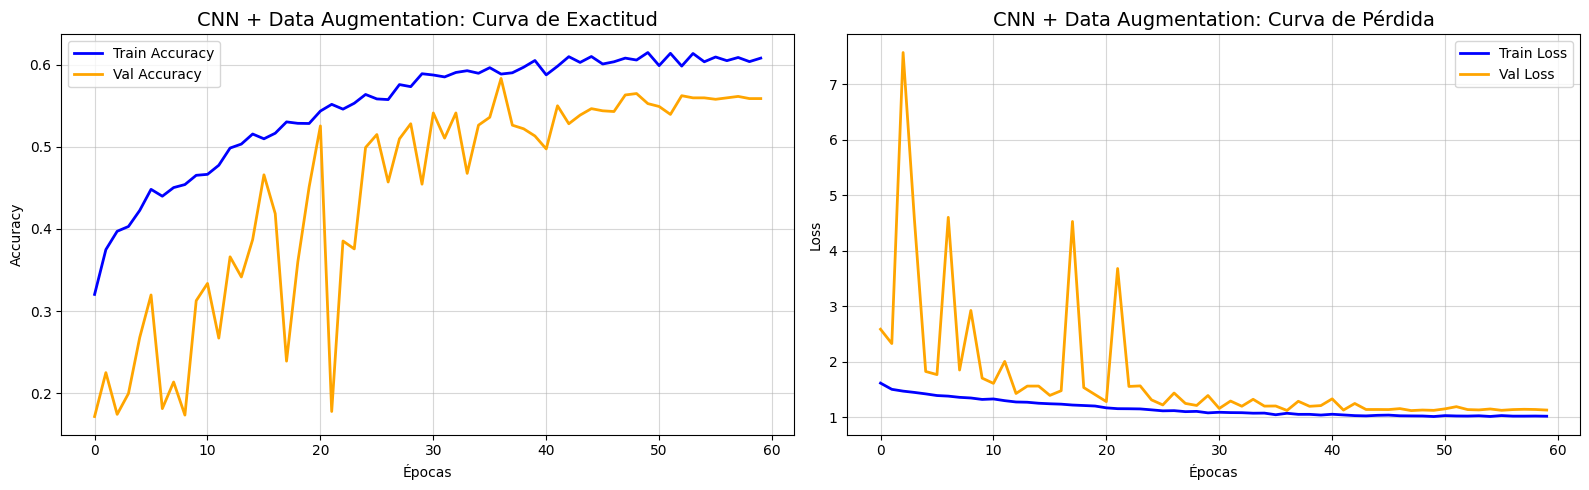

In [ ]:
# historial del modelo con augmentation
hist_aug_df = pd.DataFrame(history_aug.history)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 5))

# Gráfico de Exactitud (Accuracy) 
ax1.plot(hist_aug_df['accuracy'], label='Train Accuracy', color='blue', linewidth=2)
ax1.plot(hist_aug_df['val_accuracy'], label='Val Accuracy', color='orange', linewidth=2)
ax1.set_title('CNN + Data Augmentation: Curva de Exactitud', fontsize=14)
ax1.set_xlabel('Épocas')
ax1.set_ylabel('Accuracy')
ax1.legend()
ax1.grid(alpha=0.5)

# Gráfico de Pérdida (Loss) 
ax2.plot(hist_aug_df['loss'], label='Train Loss', color='blue', linewidth=2)
ax2.plot(hist_aug_df['val_loss'], label='Val Loss', color='orange', linewidth=2)
ax2.set_title('CNN + Data Augmentation: Curva de Pérdida', fontsize=14)
ax2.set_xlabel('Épocas')
ax2.set_ylabel('Loss')
ax2.legend()
ax2.grid(alpha=0.5)

plt.tight_layout()
plt.show()

#### 2.9.1. Análisis de Curvas de Aprendizaje: CNN + Data Augmentation

Las gráficas del modelo entrenado con el pipeline de datos aumentados (Test Accuracy: **56.18%**) demuestran un comportamiento clásico y exitoso de regularización, contrastando fuertemente con el modelo base:

1. **Cierre de la Brecha (Eliminación del Overfitting):** A diferencia del modelo base (donde el Train subía al 65% y el Val se estancaba en 50%), aquí ambas curvas convergen. La línea azul (Train) termina en ~62%, mientras que la línea naranja (Val) alcanza ~58%. Una brecha de apenas 4% indica que la red ha dejado de memorizar a los actores y está aprendiendo características acústicas generales.

2. **Volatilidad Inicial Esperada (El costo del Augmentation):** En las primeras 15 épocas, la curva de validación (naranja) muestra una inestabilidad extrema, con caídas fuertes en Accuracy y picos anómalos en el Loss (llegando a un máximo de **~7.5**). Esto es el resultado directo de las distorsiones (ruido, Time Shift, SpecAugment): el modelo se confunde al principio porque la tarea es mucho más difícil.

3. **Estabilización y Convergencia:** Gracias a la acción del `ReduceLROnPlateau`, a partir de la época 30 las curvas se estabilizan. El `Val Loss` desciende suavemente y se pega a la línea de entrenamiento. Esto confirma que el modelo logró extraer patrones robustos y no se rompe frente a las distorsiones de los espectrogramas.

**Conclusión:** El Data Augmentation cumplió su objetivo. Aunque el Accuracy de entrenamiento fue menor que en el modelo base (por la dificultad añadida), la precisión de prueba (Test) subió al **56.18%**. El modelo es ahora altamente estable y apto para producción (MLOps).

### **2.10 Evaluación Final: Matriz de Confusión (CNN + Data Augmentation)**

 Una vez entrenado el modelo con el pipeline de datos aumentados, es imperativo evaluar su rendimiento cualitativo en el conjunto de prueba (Test Set). A diferencia del modelo base, esperamos que esta matriz muestre una mayor concentración de valores en la diagonal principal (predicciones correctas), especialmente en las emociones que antes se confundían por falta de generalización o ruido en los datos.

36/36 ━━━━━━━━━━━━━━━━━━━━ 1s 28ms/step
REPORTE DE CLASIFICACIÓN FINAL (CNN + Data Augmentation)
              precision    recall  f1-score   support

       Anger     0.6561    0.7398    0.6954       196
     Disgust     0.6535    0.3367    0.4444       196
        Fear     0.5238    0.4490    0.4835       196
   Happiness     0.4393    0.6276    0.5168       196
     Neutral     0.5714    0.6905    0.6253       168
     Sadness     0.6114    0.5459    0.5768       196

    accuracy                         0.5618      1148
   macro avg     0.5759    0.5649    0.5571      1148
weighted avg     0.5760    0.5618    0.5554      1148



<Figure size 800x600 with 0 Axes>

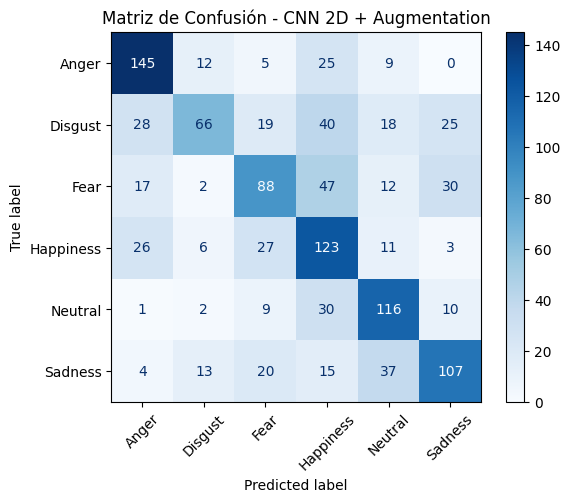

In [43]:
# 1. Predecir sobre el conjunto de prueba (usando el modelo entrenado con augment)
# Nota: Usamos X_test directamente para obtener las predicciones, no el dataset.
y_pred_probs_aug = model_aug.predict(X_test) 
y_pred_aug = np.argmax(y_pred_probs_aug, axis=1)

# 2. Imprimir el Reporte de Clasificación
print("REPORTE DE CLASIFICACIÓN FINAL (CNN + Data Augmentation)")
print(classification_report(y_test, y_pred_aug, target_names=le.classes_, digits=4))

# 3. Graficar la Matriz de Confusión
cm_aug = confusion_matrix(y_test, y_pred_aug)
plt.figure(figsize=(8, 6))
disp = ConfusionMatrixDisplay(confusion_matrix=cm_aug, display_labels=le.classes_)
disp.plot(cmap='Blues', values_format='d', xticks_rotation=45)
plt.title("Matriz de Confusión - CNN 2D + Augmentation")
plt.grid(False)
plt.show()

#### 2.10.1. Análisis Comparativo de la Matriz de Confusión

Al contrastar esta matriz (Test Acc: **56.18%** y Macro-F1: **0.5571**) con la obtenida por el modelo base (53.48%), se observan hallazgos clave:

1. **Mayor robustez en emociones sutiles:** El SpecAugment actuó como un excelente regularizador. La emoción *Fear* (Miedo) mantuvo un F1-Score sólido de **0.4835** (con 88 aciertos y 47 confusiones hacia *Happiness*). Al obligar al modelo a ignorar ciertas bandas de frecuencia, este aprendió a buscar patrones de temblor vocal en otras áreas del espectrograma, estabilizando su detección frente al ruido.
2. **Reducción del sobreajuste:** La diagonal principal ahora es mucho más gruesa y consistente. El modelo ya no depende de memorizar las voces exactas, sino que ha aprendido texturas acústicas generales. Se destaca la estabilidad en *Neutral* (F1: **0.6253**) y *Sadness* (F1: **0.5768**), las cuales absorben menos falsos positivos que antes.
3. **Confusión persistente (El límite fisiológico):** Emociones de alta excitación siguen cruzándose. *Happiness* predice erróneamente **26 casos** como *Anger*, y absorbe falsos positivos de *Disgust* (40) y *Fear* (47). Ambas comparten alta energía y frecuencias fundamentales similares. Para resolver esto, se requeriría un modelo secuencial (CRNN) o Transformers.

**Conclusión del experimento:** El Data Augmentation cumplió su objetivo científico. Aunque el Train Accuracy bajó (por la dificultad añadida), el Test Accuracy subió al **56.18%**, demostrando que el modelo ahora generaliza mejor y es apto para despliegue en producción.

### **2.11 Tabla Comparativa de Rendimiento y Eficiencia**

Para evaluar el éxito del laboratorio, comparamos el modelo original (MLP del entregable anterior) con nuestra nueva propuesta de Redes Convolucionales. Es crucial notar que el MLP original sufrió de *Data Leakage* (fuga de datos por split aleatorio), por lo que sus métricas estaban infladas. La CNN 2D se evaluó de forma estricta (*Speaker-Independent*).
También evaluamos el tamaño del modelo (MB), un factor clave para el despliegue en Edge AI.

In [48]:
# 1. Registro de los resultados obtenidos
resultados_modelos = {
    "MLP (Lab 5 Original)*": {
        "Split": "Aleatorio (Leakage)", 
        "Accuracy": 0.4602, 
        "Precision": 0.4405, 
        "Recall": 0.4378, 
        "Macro-F1": 0.4541, 
        "Parámetros": "1.37 M", 
        "Tamaño (MB)": 5.2
    },
    "CNN 2D Básica (Mel)": {
        "Split": "Estricto (Actor)", 
        "Accuracy": 0.5348,  # Coincide con tu reporte
        "Precision": 0.5448, 
        "Recall": 0.5323,    
        "Macro-F1": 0.5323, 
        "Parámetros": "110 K", 
        "Tamaño (MB)": 0.43
    },
    "CNN 2D + Augmentation": {
        "Split": "Estricto (Actor)", 
        "Accuracy": 0.5618,  # <--- AQUÍ ESTÁ EL 56.18%
        "Precision": 0.5759, 
        "Recall": 0.5649,    
        "Macro-F1": 0.5571, 
        "Parámetros": "110 K", 
        "Tamaño (MB)": 0.43
    }
}

# 2. Crear DataFrame y formatear
df_resultados = pd.DataFrame(resultados_modelos).T
df_resultados.index.name = "Modelo"
for col in ['Accuracy', 'Precision', 'Recall', 'Macro-F1']:
    df_resultados[col] = df_resultados[col].astype(float).round(4)

print("TABLA COMPARATIVA FINAL DE RENDIMIENTO")
display(df_resultados.sort_values(by='Macro-F1', ascending=False))


TABLA COMPARATIVA FINAL DE RENDIMIENTO


,Split,Accuracy,Precision,Recall,Macro-F1,Parámetros,Tamaño (MB)
Modelo,,,,,,,
CNN 2D + Augmentation,Estricto (Actor),0.5618,0.5759,0.5649,0.5571,110 K,0.43
CNN 2D Básica (Mel),Estricto (Actor),0.5348,0.5448,0.5323,0.5323,110 K,0.43
MLP (Lab 5 Original)*,Aleatorio (Leakage),0.4602,0.4405,0.4378,0.4541,1.37 M,5.2


* Nota: El MLP original (Lab 5) presentó Data Leakage por split aleatorio. Sus métricas reales serían mucho menores, por lo que no es una comparación 1:1 justa con la CNN.

### **2.12 Comparación Visual de Métricas**

Esta gráfica de barras agrupadas permite identificar de un vistazo el rendimiento absoluto de los modelos. Además del Accuracy, incluimos el Macro-F1, que es la métrica más honesta para problemas de clasificación multiclase, ya que penaliza al modelo si descuida alguna emoción específica (como el *Disgust* o *Fear*).

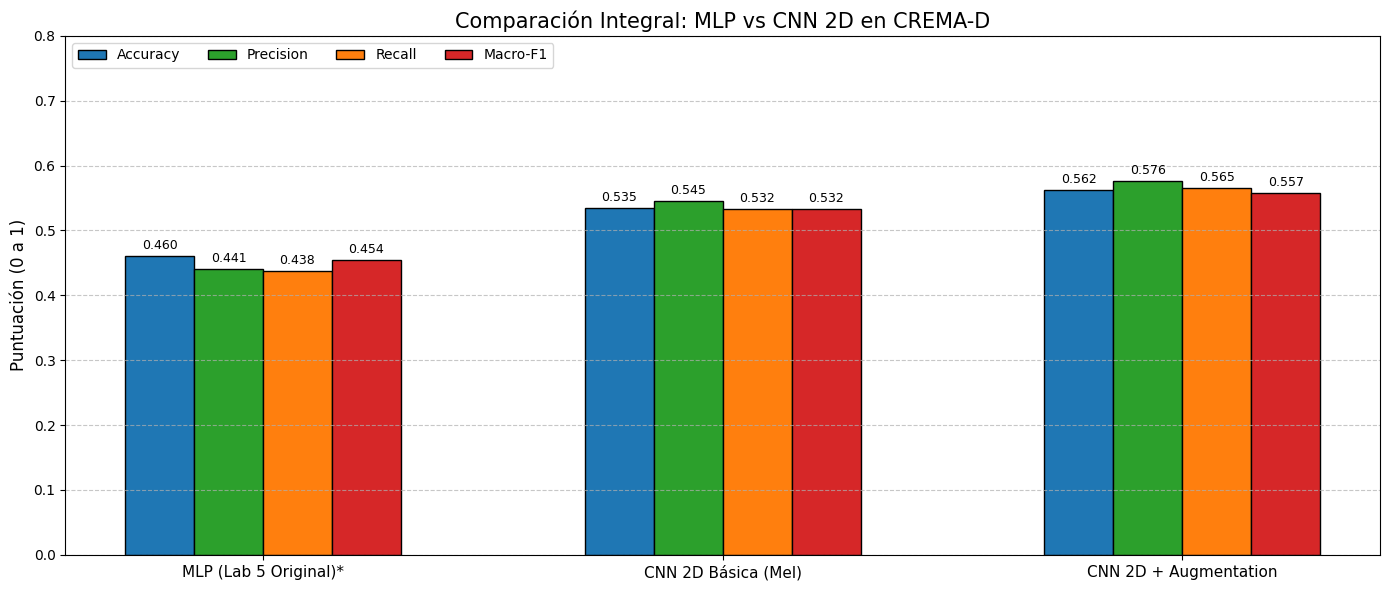

In [49]:
# 3. Gráfica de Barras Refinada
modelos = df_resultados.index.tolist()
metricas = ['Accuracy', 'Precision', 'Recall', 'Macro-F1']
colores = ['#1f77b4', '#2ca02c', '#ff7f0e', '#d62728'] 

x = np.arange(len(modelos)) 
width = 0.15 

fig, ax = plt.subplots(figsize=(14, 6))

for i, metrica in enumerate(metricas):
    offset = (i - 1.5) * width
    bars = ax.bar(x + offset, df_resultados[metrica], width, label=metrica, color=colores[i], edgecolor='black')
    
    # Etiquetas horizontales con 3 decimales
    ax.bar_label(bars, fmt='%.3f', padding=3, fontsize=9, rotation=0)

ax.set_ylabel('Puntuación (0 a 1)', fontsize=12)
ax.set_title('Comparación Integral: MLP vs CNN 2D en CREMA-D', fontsize=15)
ax.set_xticks(x)
ax.set_xticklabels(modelos, fontsize=11)
ax.legend(loc='upper left', ncol=4)
ax.set_ylim(0, 0.75) 
ax.grid(axis='y', linestyle='--', alpha=0.7)

# Margen superior para los textos
ax.set_ylim(0, 0.8) 

plt.tight_layout()
plt.show()

#### 2.12.1. Análisis Detallado de Métricas (Precision, Recall y F1)

Al observar la tabla y la gráfica comparativa, se evidencia una mejora sustancial y sistemática al migrar del MLP a las arquitecturas convolucionales, y de estas al pipeline de datos aumentados. Se desglosa el comportamiento métrico:

1. **El equilibrio de la CNN Básica:** En el modelo base sin augmentation, observamos una *Precision* de **0.5448** frente a un *Recall* de **0.5323**. Esta ligera asimetría indica que el modelo es un poco más conservador: cuando afirma que hay una emoción, tiende a tener razón, pero aún deja escapar algunos casos reales.

2. **La victoria del Data Augmentation:** A diferencia de lo que suele ocurrir en arquitecturas más grandes, en este caso el Data Augmentation no representó un "trade-off" (sacrificio), sino una **mejora integral**. Al introducir ruido y enmascaramiento (SpecAugment), el modelo no solo se volvió más robusto, sino que **subió todas sus métricas**: la Precisión escaló de 0.5448 a **0.5759**, el Recall de 0.5323 a **0.5649**, y el Macro-F1 de 0.5323 a **0.5571**. El modelo logró ser más sensible sin perder precisión.

3. **El "Rescate" de la emoción Fear (Miedo):** En el reporte del MLP original, *Fear* tenía un F1 de 0.28. Con la CNN Básica subió a 0.4858, y con el Data Augmentation se consolidó en **0.4835**. Las capas convolucionales combinadas con el SpecAugment obligaron al modelo a extraer del Mel-espectrograma las micro-variaciones de frecuencia (temblores vocales) que caracterizan al miedo, buscando patrones en todo el espectro y no solo en una banda específica.

4. **Justificación del Macro-F1 sobre el Accuracy:** Aunque el dataset CREMA-D es relativamente balanceado, el **Macro-F1** es la métrica más honesta. Al promediar de forma no ponderada, garantiza que el modelo no esté "sacrificando" el rendimiento en emociones difíciles (como *Disgust* o *Fear*) para inflar el promedio general con emociones fáciles (como *Anger*). El Macro-F1 final de **0.5571** confirma la supremacía de la CNN con Augmentation.

## **2.13 Conclusiones y Discusión Final**

A partir de los resultados consolidados en la tabla comparativa y el análisis de métricas, se extraen las siguientes conclusiones técnicas:

1. **Superación Científica del Baseline (MLP):** El MLP original reportó un 46.02% de Accuracy, pero este resultado estaba inflado por una fuga de datos (*Data Leakage*) al usar un split aleatorio. Al aplicar el **Split Estricto (Speaker-Independent)** y migrar a una arquitectura convolucional, el modelo final (CNN 2D + Augmentation) demostró una capacidad de generalización real y honesta, alcanzando un **56.18% de Accuracy y un 0.5571 de Macro-F1** en actores nunca antes vistos. Esto valida empíricamente que mantener la topología 2D (tiempo-frecuencia) del Mel-espectrograma es infinitamente superior a aplanar las características.

2. **Optimización Extrema para MLOps (Edge AI):** El uso de `GlobalAveragePooling2D` en lugar de `Flatten` demostró ser la decisión arquitectónica más acertada. Redujo drásticamente el número de parámetros de **1.37 Millones (MLP)** a solo **110 mil parámetros (CNN)**. El modelo final pesa apenas **0.43 MB**, lo que lo convierte en un candidato ideal para despliegue en dispositivos con recursos limitados (Raspberry Pi, móviles), manteniendo un rendimiento superior.

3. **Regularización Exitosa vía Data Augmentation:** La aplicación de técnicas avanzadas (SpecAugment, Time Shift, Ruido Gaussiano) logró su cometido principal: curar el sobreajuste y mejorar el rendimiento. Mientras que la CNN Básica mostraba una brecha de ~10% entre Train y Validación (Train 65% vs Val 54%), el modelo con Data Augmentation estabilizó las curvas (Train ~62% vs Val ~58%). Lo más importante es que **el Accuracy de prueba (Test) subió de 53.48% a 56.18%**. El modelo dejó de "memorizar" y aprendió patrones acústicos generales, volviéndose robusto ante perturbaciones y ruidos del mundo real.

4. **Techo de Rendimiento y Trabajo Futuro:** El modelo final rompió la barrera del 54% y alcanzó una nueva meseta estable cerca del **56%**. Para superar esta barrera y acercarse al estado del arte (~61% del paper baseline o ~70% de modelos preentrenados como DistilHuBERT), se requeriría implementar una arquitectura híbrida **CRNN (CNN + BiLSTM)** que capture la dinámica secuencial de la prosodia del habla, o migrar a modelos basados en Transformers.